# Swasthya Saathi: finding the right care, with evidence

**Input:** a free-text request (English / Hindi / Hinglish) + a location. **Output:** an urgency-appropriate referral plan with **WHY** (cited evidence) and **HOW** (the model's logic and odds).

```
OFFLINE (builds Delta tables)                         ONLINE  recommend(query, location)
S0 Ingest: Virtue + PM-JAY + state schemes            Q1 Normalise query (voice → text upstream)
   + de-empanelled/suspended (+PMNDP, NABH)           Q2 Urgency & needs translator (ensemble, cost-sensitive)
S1 Record forensics + probabilistic registry linking  Q3 Candidate retrieval (reachable in time)
S2 Truth discovery with government referees           Q4 Clock-aware planner (Monte Carlo, stabilise→transfer)
S3 Capability knowledge graph (link prediction)       Q5 Conformal shortlist + Pandora call order
S4 Supervised stacker trained on government lists     Q6 Evidence court (verified quotes, can only lower)
S5 Fusion → P(capability) with ranges, evidence cards Q7 Urgency-appropriate answer: WHY + HOW + uncertainty
```
**Leakage control:** facilities matched to a government list are split into **train / calib / test** folds. Test-fold labels are never seen by S2 or S4, and every accuracy number reported comes from the test fold.

In [0]:
%pip install rapidfuzz shap --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import os, re, json, math, glob, hashlib, warnings, unicodedata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.stats import beta as beta_dist
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.neighbors import LocalOutlierFactor, BallTree, KNeighborsRegressor
from sklearn.model_selection import cross_val_predict, StratifiedKFold, GroupKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
warnings.filterwarnings("ignore")
try:
    from rapidfuzz import fuzz, process
except ImportError:  # slow fallback
    import difflib
    class fuzz:
        @staticmethod
        def ratio(a, b): return 100 * difflib.SequenceMatcher(None, a, b).ratio()
        token_set_ratio = ratio
    process = None
try:
    import shap
except ImportError:
    shap = None

# ---------------- CONFIG ----------------
SRC = "databricks_virtue_foundation_dataset_dais_2026.virtue_foundation_dataset"
OUT_CATALOG, OUT_SCHEMA = "workspace", "care_finder"
OUT = f"{OUT_CATALOG}.{OUT_SCHEMA}"
EXT_DIR = f"/Volumes/{OUT_CATALOG}/{OUT_SCHEMA}/external"
LLM_ENDPOINT = "databricks-meta-llama-3-3-70b-instruct"
USE_LLM = True
ROAD_FACTOR, SPEED_KMH, DISPATCH_MIN = 1.35, 35.0, 5.0
N_SIMS = 1000
RS = 42
TODAY = pd.Timestamp(datetime.now(timezone.utc).date())
INDIA_BBOX = (6.0, 37.6, 68.0, 97.6)
try:
    spark.sql(f"CREATE SCHEMA IF NOT EXISTS {OUT}")
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {OUT}.external")
except Exception as e:
    print("schema/volume:", e)

def load_table(name):
    return spark.table(name).toPandas()

def save(df, name):
    """Write a pandas frame to Delta (lists/dicts → JSON strings)."""
    out = df.copy()
    for c in out.columns:
        if out[c].dtype == object:
            out[c] = out[c].map(lambda v: json.dumps(v, default=str) if isinstance(v, (list, dict, tuple, np.ndarray))
                                else ("" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)))
        elif str(out[c].dtype).startswith("datetime"):
            out[c] = out[c].astype(str)
    spark.createDataFrame(out).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{OUT}.{name}")
    print(f"saved {OUT}.{name}  {out.shape}")

try:
    display
except NameError:
    def display(x): print(x.head(20) if hasattr(x, "head") else x)

## Service ontology
Each capability has **claim patterns**, **specialty codes** (Virtue's camelCase taxonomy), **prerequisite groups** (based on IPHS / NABH norms) and **PM-JAY specialty keywords** (used to read the government lists).
Each condition maps to a **stabilise** set (what a nearer facility needs to keep the patient alive) and a **definitive** set, plus a **clock τ**: benefit decays as `exp(-t/τ)`. These are literature-informed assumptions and are stated as such.

In [0]:
SERVICES = {
 "emergency_24x7": dict(label="24/7 emergency care", hi="24 घंटे इमरजेंसी",
    kw=[r"24\s*[x/*×]\s*7", r"24 ?(hrs?|hours?)", r"\bemergency\b", r"\bcasualty\b", r"round[- ]the[- ]clock"],
    spec=["emergencymedicine"], prereq=[[r"ambulance"], [r"\bicu\b|intensive"], [r"laborator|\blab\b"]], pmjay=[r"emergency"]),
 "blood_bank": dict(label="blood bank / transfusion", hi="ब्लड बैंक",
    kw=[r"blood bank", r"blood storage", r"blood transfusion", r"blood centre"], spec=[],
    prereq=[[r"patholog|laborator"]], pmjay=[]),
 "icu": dict(label="ICU", hi="आईसीयू",
    kw=[r"\bicu\b", r"intensive care", r"critical care", r"\bhdu\b"], spec=["criticalcare"],
    prereq=[[r"ventilator"], [r"monitor"], [r"oxygen"]], pmjay=[r"critical care"]),
 "obstetric_surgery": dict(label="C-section / emergency obstetrics", hi="सिजेरियन / प्रसूति ऑपरेशन",
    kw=[r"c[- ]?section", r"ca?esarean", r"\blscs\b", r"obstetric", r"labou?r room", r"maternity"],
    spec=["obstetric", "gynecolog"], prereq=[[r"ana?esthe"], [r"operation theat|\bot\b|operating (room|theat)"], [r"blood bank|blood storage"]],
    pmjay=[r"obstetric", r"gyna?ec"]),
 "nicu": dict(label="NICU (newborn intensive care)", hi="नवजात आईसीयू (NICU)",
    kw=[r"\bnicu\b", r"neonatal (intensive|icu)", r"\bsncu\b", r"newborn (care|icu)"], spec=["neonatolog"],
    prereq=[[r"incubator|radiant warmer"], [r"phototherapy"], [r"ventilator|cpap"]], pmjay=[r"neo-?nat"]),
 "dialysis": dict(label="dialysis", hi="डायलिसिस",
    kw=[r"dialysis", r"ha?emodialysis", r"\bcapd\b"], spec=["nephrolog"],
    prereq=[[r"nephrolog"], [r"\bro\b|reverse osmosis"], [r"dialy[sz]"]], pmjay=[r"nephrolog", r"dialysis"]),
 "ct_scan": dict(label="CT scan", hi="सीटी स्कैन",
    kw=[r"\bct\b", r"computed tomography", r"ct scan", r"\d+ ?slice"], spec=[], prereq=[[r"radiolog"]], pmjay=[]),
 "mri": dict(label="MRI scan", hi="एमआरआई",
    kw=[r"\bmri\b", r"magnetic resonance"], spec=[], prereq=[[r"radiolog"]], pmjay=[]),
 "trauma_surgery": dict(label="trauma & fracture surgery", hi="दुर्घटना / हड्डी सर्जरी",
    kw=[r"trauma", r"polytrauma", r"fracture", r"accident"], spec=["orthopedic", "traumasurg"],
    prereq=[[r"operation theat|\bot\b"], [r"x[- ]?ray|\bct\b"], [r"blood bank|blood storage"]], pmjay=[r"polytrauma", r"orthop"]),
 "cardiac_cath": dict(label="heart attack care (cath lab)", hi="हार्ट अटैक इलाज (कैथ लैब)",
    kw=[r"cath ?lab", r"angioplasty", r"angiograph", r"\bptca\b", r"\bpci\b", r"thromboly"], spec=["interventionalcardio", "cardiolog"],
    prereq=[[r"\bccu\b|\biccu\b|cardiac icu"], [r"echo|\becg\b|\bekg\b"]], pmjay=[r"cardiolog"]),
 "cardiac_surgery": dict(label="cardiac surgery", hi="हृदय सर्जरी",
    kw=[r"cardiac surg", r"cardiothoracic", r"\bctvs\b", r"bypass surg", r"\bcabg\b", r"open heart", r"valve replacement"],
    spec=["cardiothoracic", "cardiacsurg"], prereq=[[r"heart[- ]lung|perfusion"], [r"cath ?lab"], [r"\bicu\b|\biccu\b"]],
    pmjay=[r"cardio[- ]?thoracic", r"\bctvs\b", r"cardiac surg"]),
 "stroke_neuro": dict(label="stroke / neurology care", hi="लकवा / न्यूरो इलाज",
    kw=[r"stroke", r"neurolog", r"neurosurg"], spec=["neurolog", "neurosurg"],
    prereq=[[r"\bct\b|\bmri\b"], [r"\bicu\b"]], pmjay=[r"neurolog", r"neuro-?surg"]),
 "burn_care": dict(label="burn care", hi="जलने का इलाज",
    kw=[r"burns? (unit|ward|care|icu|centre|center|management)", r"\bburns\b"], spec=["plasticsurg"],
    prereq=[[r"plastic surg|skin graft"], [r"\bicu\b"]], pmjay=[r"burn"]),
 "oncology": dict(label="cancer treatment", hi="कैंसर इलाज",
    kw=[r"oncolog", r"chemotherapy", r"radiotherapy|radiation therapy", r"\bcancer\b"], spec=["oncolog"],
    prereq=[[r"linac|linear accelerator|cobalt"], [r"patholog|histopath"], [r"chemo"]], pmjay=[r"oncolog", r"cancer", r"chemotherapy"]),
 "antivenom_poison": dict(label="snakebite / poisoning treatment", hi="सांप काटने / ज़हर का इलाज",
    kw=[r"anti[- ]?snake", r"\basv\b", r"snake ?bite", r"poison", r"toxicolog", r"anti[- ]?venom"], spec=["toxicolog"],
    prereq=[[r"\bicu\b|ventilator"]], pmjay=[]),
}
SVC = list(SERVICES)
TIERS = ["immediate", "urgent", "soon", "planned"]
TIER_TAU = {"immediate": 60, "urgent": 240, "soon": 3 * 24 * 60, "planned": 14 * 24 * 60}     # minutes
TIER_WINDOW = {"immediate": 60, "urgent": 240, "soon": 24 * 60, "planned": 7 * 24 * 60}     # "in time" for reporting
TIER_ALPHA = {"immediate": 0.20, "urgent": 0.10, "soon": 0.10, "planned": 0.05}             # conformal miscoverage

CONDITIONS = {
 "road_trauma":           dict(tier="immediate", tau=60,  stabilise=["emergency_24x7", "blood_bank"], definitive=["trauma_surgery", "ct_scan"], label="serious injury / accident"),
 "obstetric_haemorrhage": dict(tier="immediate", tau=60,  stabilise=["emergency_24x7", "blood_bank"], definitive=["obstetric_surgery", "blood_bank"], label="heavy bleeding around childbirth"),
 "labour_csection":       dict(tier="urgent",    tau=180, stabilise=["emergency_24x7"], definitive=["obstetric_surgery"], label="difficult labour / C-section"),
 "sick_newborn":          dict(tier="immediate", tau=90,  stabilise=["emergency_24x7"], definitive=["nicu"], label="very sick newborn"),
 "heart_attack":          dict(tier="immediate", tau=90,  stabilise=["emergency_24x7", "icu"], definitive=["cardiac_cath"], label="possible heart attack"),
 "stroke":                dict(tier="immediate", tau=120, stabilise=["emergency_24x7", "ct_scan"], definitive=["stroke_neuro", "ct_scan"], label="possible stroke / paralysis"),
 "snakebite_poisoning":   dict(tier="immediate", tau=90,  stabilise=["antivenom_poison"], definitive=["antivenom_poison", "icu"], label="snakebite or poisoning"),
 "burns":                 dict(tier="immediate", tau=120, stabilise=["emergency_24x7"], definitive=["burn_care"], label="burns"),
 "general_emergency":     dict(tier="immediate", tau=60,  stabilise=["emergency_24x7"], definitive=["emergency_24x7", "icu"], label="medical emergency"),
 "dialysis_need":         dict(tier="urgent",    tau=24 * 60, stabilise=[], definitive=["dialysis"], label="dialysis"),
 "imaging_ct":            dict(tier="soon",      tau=None, stabilise=[], definitive=["ct_scan"], label="CT scan"),
 "imaging_mri":           dict(tier="planned",   tau=None, stabilise=[], definitive=["mri"], label="MRI scan"),
 "cancer_care":           dict(tier="planned",   tau=None, stabilise=[], definitive=["oncology"], label="cancer treatment"),
 "cardiac_surgery":       dict(tier="planned",   tau=None, stabilise=[], definitive=["cardiac_surgery"], label="heart surgery"),
 "nicu_planned":          dict(tier="soon",      tau=None, stabilise=[], definitive=["nicu"], label="newborn intensive care"),
}

## Helpers

In [0]:
def clean_str(v):
    if v is None: return ""
    if isinstance(v, float) and np.isnan(v): return ""
    s = str(v).strip()
    return "" if s.lower() in ("null", "none", "nan", "[]", "{}") else s

def parse_list(v):
    if isinstance(v, (list, tuple, np.ndarray)):
        return [str(x) for x in v if x is not None and clean_str(x)]
    s = clean_str(v)
    if not s: return []
    if s.startswith("["):
        try:
            return [str(x) for x in json.loads(s) if x is not None and clean_str(x)]
        except Exception:
            pass
    return [s]

def uniq(xs):
    seen, out = set(), []
    for x in xs:
        k = x.lower().strip()
        if k and k not in seen:
            seen.add(k); out.append(x.strip())
    return out

def to_num(v):
    s = clean_str(v)
    m = re.search(r"\d+(\.\d+)?", s.replace(",", ""))
    return float(m.group(0)) if m else np.nan

def camel_words(s):
    return re.sub(r"(?<!^)(?=[A-Z])", " ", s).lower()

def norm_place(s):
    s = unicodedata.normalize("NFKD", clean_str(s)).lower()
    s = re.sub(r"\b(district|dist|city|urban|rural|nagar nigam)\b", " ", s)
    return re.sub(r"[^a-z]", "", s)

def digits10(p):
    d = re.sub(r"\D", "", clean_str(p))
    return d[-10:] if len(d) >= 10 else ""

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def in_india(lat, lon):
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    return (lat >= INDIA_BBOX[0]) & (lat <= INDIA_BBOX[1]) & (lon >= INDIA_BBOX[2]) & (lon <= INDIA_BBOX[3])

def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
def sigmoid(x): return 1 / (1 + np.exp(-x))

GENERIC = r"\b(hospitals?|clinics?|nursing ?home|pvt|private|ltd|limited|multi ?-?speciality|multi ?-?specialty|super ?-?speciality|speciality|specialty|centre|center|dr\.?|doctor'?s?|the|and|medical|institute|trust|research|&)\b"
def phonetic(s):
    s = re.sub(r"[^a-z ]", " ", clean_str(s).lower())
    s = re.sub(GENERIC, " ", s)
    for a, b in [("ee", "i"), ("oo", "u"), ("aa", "a"), ("w", "v"), ("ph", "f"), ("sh", "s"), ("z", "j"),
                 ("th", "t"), ("dh", "d"), ("bh", "b"), ("kh", "k"), ("gh", "g"), ("ck", "k"), ("q", "k"), ("y ", "i ")]:
        s = s.replace(a, b)
    s = re.sub(r"([bcdfgjklmnprstv])h", r"\1", s)
    s = re.sub(r"(.)\1+", r"\1", s)
    return re.sub(r"\s+", " ", s).strip()

def name_sim(a, b):
    pa, pb = phonetic(a), phonetic(b)
    s1 = fuzz.token_set_ratio(clean_str(a).lower(), clean_str(b).lower())
    s2 = fuzz.token_set_ratio(pa, pb) if pa and pb else 0
    return max(s1, s2)

# S0 · Ingest
### 1. Virtue facilities (the core dataset)

In [0]:
fac_raw = load_table(f"{SRC}.facilities")
print("facilities:", fac_raw.shape)

F = pd.DataFrame({"fid": fac_raw["unique_id"].astype(str).values})
F["name"] = fac_raw["name"].map(clean_str).values
for c, src in [("spec", "specialties"), ("proc", "procedure"), ("equip", "equipment"), ("cap", "capability"),
               ("phones", "phone_numbers"), ("websites", "websites"), ("urls", "source_urls"),
               ("stypes", "source_types"), ("sids", "source_ids")]:
    F[c] = fac_raw[src].map(parse_list).map(uniq).values
F["desc"] = fac_raw["description"].map(clean_str).values
F["official_phone"] = fac_raw["officialPhone"].map(clean_str).values
F["official_site"] = fac_raw["officialWebsite"].map(clean_str).str.lower().values
F["city"] = fac_raw["address_city"].map(clean_str).values
F["state"] = fac_raw["address_stateOrRegion"].map(clean_str).values
F["address"] = (fac_raw[["address_line1", "address_line2", "address_line3"]].fillna("").astype(str)
                .apply(lambda r: ", ".join(clean_str(x) for x in r if clean_str(x)), axis=1).values)
F["pin"] = fac_raw["address_zipOrPostcode"].astype(str).str.extract(r"(\d{6})")[0].values
F["lat0"] = pd.to_numeric(fac_raw["latitude"], errors="coerce").values
F["lon0"] = pd.to_numeric(fac_raw["longitude"], errors="coerce").values
F["doctors"] = fac_raw["numberDoctors"].map(to_num).values
F["beds"] = fac_raw["capacity"].map(to_num).values
F["year"] = fac_raw["yearEstablished"].map(to_num).values
F.loc[(F.year < 1850) | (F.year > TODAY.year), "year"] = np.nan
F["ftype"] = fac_raw["facilityTypeId"].map(clean_str).str.lower().values
F["operator"] = fac_raw["operatorTypeId"].map(clean_str).str.lower().values
F["page_update"] = pd.to_datetime(fac_raw["recency_of_page_update"].map(clean_str), errors="coerce").values
F["last_post"] = pd.to_datetime(fac_raw["post_metrics_most_recent_social_media_post_date"].map(clean_str), errors="coerce").values
F["followers"] = fac_raw["engagement_metrics_n_followers"].map(to_num).values
F["n_social"] = fac_raw["distinct_social_media_presence_count"].map(to_num).values
F["cluster_id"] = fac_raw["cluster_id"].map(clean_str).values

# Text per field (camelCase specialty codes - words so regexes match them)
F["t_name"] = F.name.str.lower()
F["t_spec"] = F.spec.map(lambda xs: " ; ".join(camel_words(x) for x in xs))
for c in ["proc", "equip", "cap"]:
    F[f"t_{c}"] = F[c].map(lambda xs: " ; ".join(xs).lower())
F["t_desc"] = F.desc.str.lower()
FIELDS = ["name", "spec", "proc", "equip", "cap", "desc"]
FIELD_LABEL = {"name": "facility name", "spec": "specialties", "proc": "procedures", "equip": "equipment", "cap": "capabilities", "desc": "description"}
F["t_all"] = F[[f"t_{f}" for f in FIELDS]].agg(" | ".join, axis=1)
F["spec_codes"] = F.spec.map(lambda xs: " ".join(x.lower() for x in xs))

# Source-domain classes: which kinds of websites stand behind each record
DOMAIN_CLASSES = {
    "gov": [r"\.gov\.in", r"\.nic\.in", r"pmjay", r"nabh", r"nhp\.gov"],
    "directory": [r"justdial", r"practo", r"sulekha", r"lybrate", r"indiamart", r"onefivenine", r"meddco", r"credihealth",
                  r"medindia", r"hospitalsinindia", r"indiabyroad", r"asklaila", r"grotal", r"vaidam", r"clinicspots", r"bajajfinserv",
                  r"palliumindia", r"palliativecare", r"quikr", r"healthfrog", r"docprime", r"apollo247", r"1mg"],
    "social": [r"facebook\.", r"instagram\.", r"twitter\.", r"\bx\.com", r"linkedin\.", r"youtube\."],
    "irrelevant": [r"magicbricks", r"99acres", r"housing\.com", r"nobroker", r"restaurant", r"zomato", r"swiggy", r"tripadvisor",
                   r"wikimapia", r"commonfloor", r"makaan"],
}
def domain_of(u):
    u = clean_str(u).lower()
    u = re.sub(r"^https?://", "", u); u = re.sub(r"^www\.", "", u)
    return u.split("/")[0]
def classify_domains(row):
    doms = {domain_of(u) for u in row.websites + row.urls if clean_str(u)}
    own = domain_of(row.official_site) if row.official_site else ""
    classes = set()
    for d in doms:
        hit = [k for k, pats in DOMAIN_CLASSES.items() if any(re.search(p, d) for p in pats)]
        if hit: classes.update(hit)
        elif own and d == own: classes.add("own_site")
        else:
            toks = [t for t in re.findall(r"[a-z]{4,}", row["name"].lower()) if t not in ("hospital", "clinic", "medical", "health", "care", "centre", "center")]
            classes.add("own_site" if any(t in d for t in toks) else "other_web")
    return sorted(classes), len(doms)
_dc = F.apply(classify_domains, axis=1)
F["src_classes"] = _dc.map(lambda x: x[0]); F["n_domains"] = _dc.map(lambda x: x[1])
F["stype_set"] = F.stypes.map(lambda xs: sorted({x.lower() for x in xs}))
print(F.src_classes.explode().value_counts())

facilities: (10088, 51)
src_classes
social        9036
own_site      8465
other_web     7949
directory     7118
gov           1013
irrelevant     196
Name: count, dtype: int64


### 2. Public reference data: PIN directory and NFHS-5

In [0]:
pin_raw = load_table(f"{SRC}.india_post_pincode_directory")
pin_raw.columns = [c.lower() for c in pin_raw.columns]
pin_raw["latitude"] = pd.to_numeric(pin_raw["latitude"], errors="coerce")
pin_raw["longitude"] = pd.to_numeric(pin_raw["longitude"], errors="coerce")
pin_raw["pincode"] = pin_raw["pincode"].astype(str).str.extract(r"(\d{6})")[0]
pin_ok = pin_raw[in_india(pin_raw.latitude, pin_raw.longitude)].copy()

def fast_mode(df, key, col):
    # most frequent value of `col` per `key`, vectorized
    return (df.groupby([key, col]).size().reset_index(name="n")
              .sort_values([key, "n"], ascending=[True, False])
              .drop_duplicates(key).set_index(key)[col])

# Grain is post office, NOT pin: aggregate to one centroid per PIN to avoid fan-out
g = pin_ok.groupby("pincode")
PIN = pd.DataFrame({"pin_lat": g.latitude.median(), "pin_lon": g.longitude.median(),
                    "pin_spread_km": (g.latitude.max() - g.latitude.min()) * 111})
PIN["pin_district"] = fast_mode(pin_ok, "pincode", "district")
PIN["pin_state"] = fast_mode(pin_ok, "pincode", "statename")
PIN = PIN.reset_index()

pin_valid = pin_raw.dropna(subset=["pincode"])
pin_any = pd.DataFrame({"pin_district": fast_mode(pin_valid, "pincode", "district"),
                        "pin_state": fast_mode(pin_valid, "pincode", "statename")}).reset_index()

DIST_CENT = pin_ok.groupby(["statename", "district"]).agg(d_lat=("latitude", "median"), d_lon=("longitude", "median"),
                                                          n_po=("pincode", "size")).reset_index()
nfhs = load_table(f"{SRC}.nfhs_5_district_health_indicators")
print("PIN rows:", len(pin_raw), "| PINs geocoded:", len(PIN), "| NFHS:", nfhs.shape)

PIN rows: 165627 | PINs geocoded: 19550 | NFHS: (706, 109)


### 3. Government referee lists (external, uploaded to the volume)
Put CSVs in `EXT_DIR`, named by prefix (columns are matched loosely, so the exact header names don't matter):

| prefix | registry | key columns |
|---|---|---|
| `pmjay*.csv` | PM-JAY empanelled hospitals | hospital id, name, state, district, (pincode), (phone), type, **specialities** |
| `state_<scheme>*.csv` | state schemes (MJPJAY, Aarogyasri, CMCHIS…) | same as PM-JAY |
| `deempanel*.csv` | de-empanelled / suspended / **withdrawn** | hospital id/name, state, district, **status**, **date** (withdrawn = voluntary exit: no penalty, just no longer accepts the card) |
| `pmndp*.csv` | PM National Dialysis Programme centres | name, state, district |
| `nabh*.csv` | NABH-accredited | name, state, city |

Without these files the pipeline still runs, using **silver labels** from truth discovery; the validation section says which mode was used.

In [0]:
COLMAP = {"hospital_id": ["hospital_id", "hosp_id", "hospital code", "id"], "name": ["hospital_name", "hospital name", "name of", "name", "hospital", "facility"],
          "state": ["state"], "district": ["district", "city", "location"], "pincode": ["pincode", "pin", "postcode", "zip"],
          "phone": ["phone", "contact", "mobile"], "specialties": ["special"], "hospital_type": ["type", "ownership", "sector", "category"],
          "status": ["status", "action", "remark"], "date": ["date"], "lat": ["latitude", "lat"], "lon": ["longitude", "lon", "lng"],
          "address": ["address"]}
def harmonise(df):
    cols = {c: c.lower().strip() for c in df.columns}; used, out = set(), {}
    for tgt, keys in COLMAP.items():
        for k in keys:
            hit = next((c for c, l in cols.items() if k in l and c not in used), None)
            if hit: out[tgt] = df[hit]; used.add(hit); break
    return pd.DataFrame(out)

def load_registries():
    frames = []
    files = sorted(glob.glob(os.path.join(EXT_DIR, "*.csv"))) if os.path.isdir(EXT_DIR) else []
    for fp in files:
        base = os.path.basename(fp).lower()
        reg = ("pmjay" if base.startswith("pmjay") else base.split(".")[0] if base.startswith("state_") else
               "deempanel" if base.startswith("deempanel") else "pmndp" if base.startswith("pmndp") else
               "nabh" if base.startswith("nabh") else None)
        if reg is None: continue
        h = harmonise(pd.read_csv(fp, dtype=str, encoding_errors="ignore")); h["registry"] = reg; h["file"] = base
        frames.append(h); print(f"{base}: {len(h)} rows → {reg}")
    if not frames:
        print("⚠️  No referee files found in", EXT_DIR, "→ running in SILVER-LABEL mode")
        return pd.DataFrame(columns=["reg_id", "registry", "name", "state", "district", "pincode", "phone", "specialties", "hospital_type", "status", "date", "lat", "lon"])
    R = pd.concat(frames, ignore_index=True)
    for c in ["hospital_id", "name", "state", "district", "pincode", "phone", "specialties", "hospital_type", "status", "date", "lat", "lon", "address"]:
        if c not in R: R[c] = ""
    R = R.fillna("")
    R["pincode"] = R.pincode.astype(str).str.extract(r"(\d{6})")[0].fillna("")
    miss = R.pincode == ""
    R.loc[miss, "pincode"] = R.loc[miss, "address"].astype(str).str.extract(r"\b(\d{6})\b")[0].fillna("")
    R["specialties"] = R.specialties.map(lambda s: [x.strip() for x in re.split(r"[,;|/\n]", clean_str(s)) if x.strip()])
    R["date"] = pd.to_datetime(R.date, errors="coerce", dayfirst=True)
    R["lat"] = pd.to_numeric(R.lat, errors="coerce"); R["lon"] = pd.to_numeric(R.lon, errors="coerce")
    R["reg_id"] = R.registry + ":" + np.where(R.hospital_id.astype(str).str.len() > 0, R.hospital_id.astype(str), R.index.astype(str))
    # State schemes merged into PMJAY share hospital ids: keep one row per (registry, id)
    R = R.drop_duplicates(["registry", "reg_id"])
    return R[["reg_id", "registry", "name", "state", "district", "pincode", "phone", "specialties", "hospital_type", "status", "date", "lat", "lon"]]

R = load_registries()
HAVE_REFEREES = R.registry.isin(["pmjay", "pmndp"]).any() or R.registry.str.startswith("state_").any()
print("Registry rows:", len(R), "| referee mode:", "GOLD (government lists)" if HAVE_REFEREES else "SILVER")

deempanel_cghs_withdrawn.csv: 72 rows → deempanel
deempanel_hr.csv: 50 rows → deempanel
deempanel_hr_cchf.csv: 25 rows → deempanel
deempanel_hr_suspended.csv: 48 rows → deempanel
deempanel_hr_withdrawn.csv: 28 rows → deempanel
nabh_delhi_ncr_from_cghs.csv: 179 rows → nabh
pmjay_hr_ambala.csv: 72 rows → pmjay
pmjay_hr_kaithal.csv: 31 rows → pmjay
pmjay_hr_rewari.csv: 51 rows → pmjay
pmjay_jh_seraikela.csv: 22 rows → pmjay
pmjay_up_ballia.csv: 62 rows → pmjay
pmjay_up_etawah.csv: 48 rows → pmjay
pmjay_up_lucknow.csv: 322 rows → pmjay
state_cghs_delhi_ncr.csv: 424 rows → state_cghs_delhi_ncr
Registry rows: 1434 | referee mode: GOLD (government lists)


# EDA

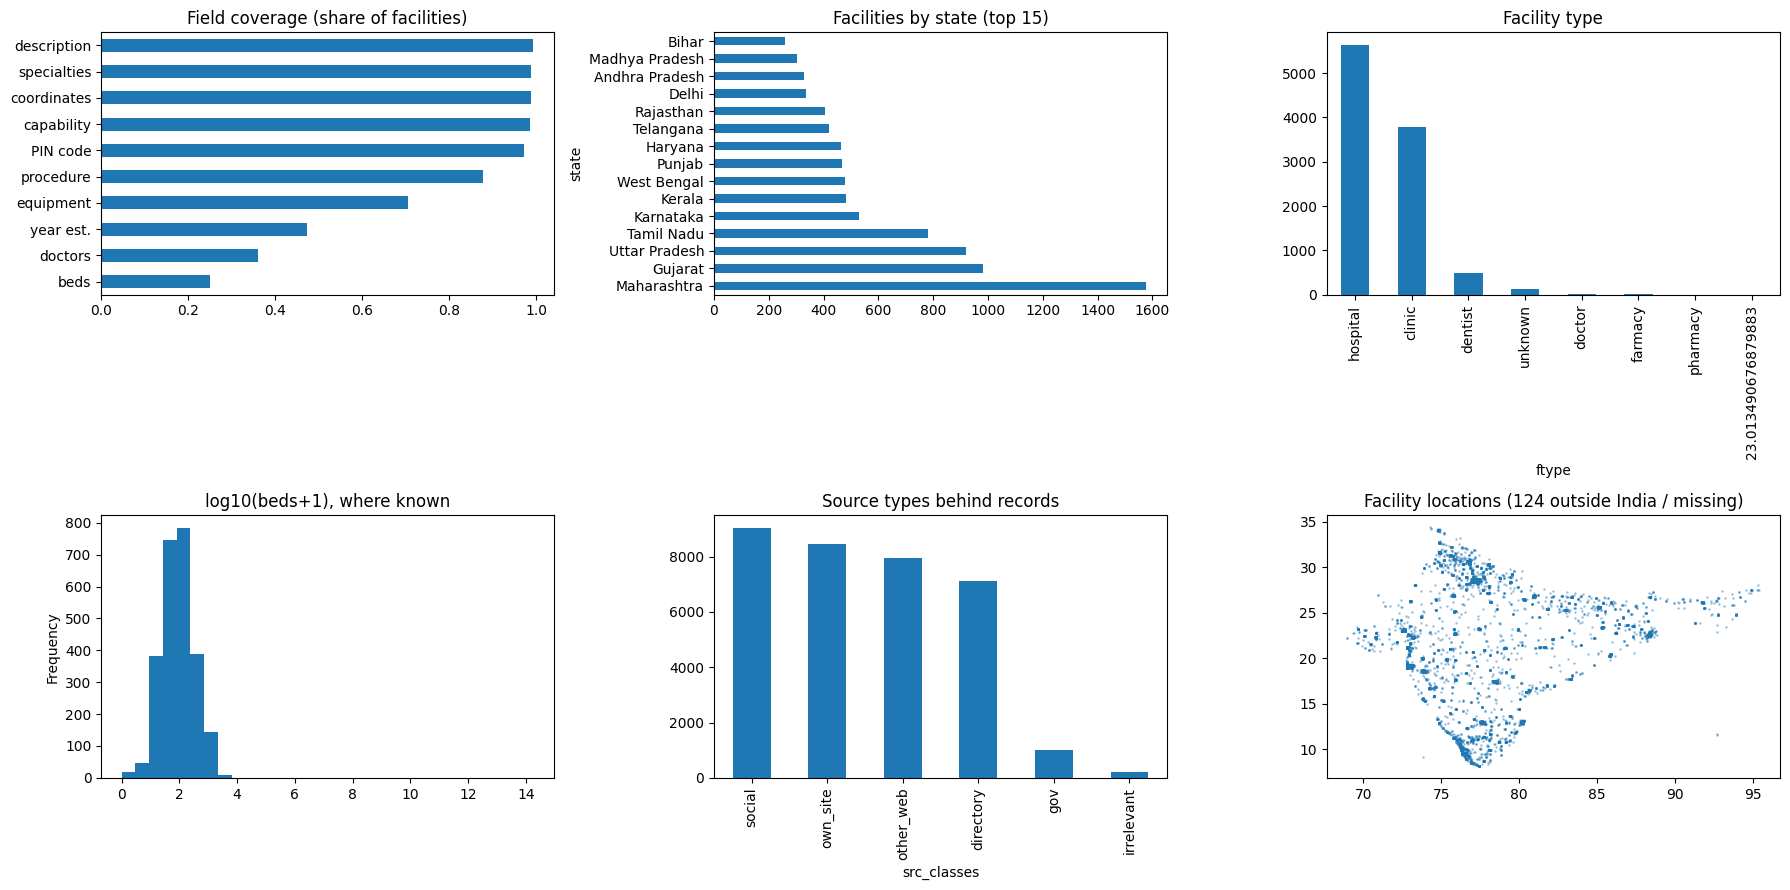

Records with >1 source id: 0.642
Median #specialties / #capability claims: 9.0 / 18.0
Coordinates outside India: 6 | missing: 118
Website not updated in >3 yrs: 0.071


In [0]:
import matplotlib.pyplot as plt
cov = pd.Series({
    "description": (F.desc != "").mean(), "capability": F.cap.map(len).gt(0).mean(),
    "procedure": F.proc.map(len).gt(0).mean(), "equipment": F.equip.map(len).gt(0).mean(),
    "specialties": F.spec.map(len).gt(0).mean(), "doctors": F.doctors.notna().mean(),
    "beds": F.beds.notna().mean(), "year est.": F.year.notna().mean(),
    "PIN code": F.pin.notna().mean(), "coordinates": F.lat0.notna().mean()}).sort_values()
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
cov.plot.barh(ax=ax[0, 0], title="Field coverage (share of facilities)")
F.state.replace("", "unknown").value_counts().head(15).plot.barh(ax=ax[0, 1], title="Facilities by state (top 15)")
F.ftype.replace("", "unknown").value_counts().head(8).plot.bar(ax=ax[0, 2], title="Facility type")
np.log10(F.beds.dropna() + 1).plot.hist(bins=30, ax=ax[1, 0], title="log10(beds+1), where known")
F.src_classes.explode().value_counts().plot.bar(ax=ax[1, 1], title="Source types behind records")
ok = in_india(F.lat0, F.lon0)
ax[1, 2].scatter(F.lon0[ok], F.lat0[ok], s=1, alpha=.3); ax[1, 2].set_title(f"Facility locations ({(~ok).sum()} outside India / missing)")
plt.tight_layout(); plt.show()

print("Records with >1 source id:", round((F.sids.map(lambda x: len(set(x))) > 1).mean(), 3))
print("Median #specialties / #capability claims:", F.spec.map(len).median(), "/", F.cap.map(len).median())
print("Coordinates outside India:", int((~ok & F.lat0.notna()).sum()), "| missing:", int(F.lat0.isna().sum()))
print("Website not updated in >3 yrs:", round(((TODAY - pd.to_datetime(F.page_update)).dt.days > 3*365).mean(), 3))

# S1 · Record forensics + probabilistic registry linking
**1a. Geo forensics:** compare coordinates with the facility's own PIN centroid, detect swapped lat/lon, and flag points outside India.

In [0]:
F = F.merge(PIN, left_on="pin", right_on="pincode", how="left").drop(columns="pincode")
F = F.merge(pin_any.rename(columns={"pin_district": "pin_district_any", "pin_state": "pin_state_any"}), left_on="pin", right_on="pincode", how="left").drop(columns="pincode")
F["pin_district"] = F.pin_district.fillna(F.pin_district_any); F["pin_state"] = F.pin_state.fillna(F.pin_state_any)
F["district"] = F.pin_district.fillna("").where(F.pin_district.fillna("") != "", F.city)

ok0 = in_india(F.lat0, F.lon0)
swap_ok = in_india(F.lon0, F.lat0) & ~ok0
F["d_pin_km"] = haversine(F.lat0, F.lon0, F.pin_lat, F.pin_lon)
F["d_pin_swapped_km"] = haversine(F.lon0, F.lat0, F.pin_lat, F.pin_lon)
F["geo_invalid"] = ~ok0 & ~swap_ok
F["geo_swapped"] = swap_ok & ((F.d_pin_swapped_km < 30) | F.pin_lat.isna())
F["geo_conflict"] = ok0 & (F.d_pin_km > 25)
print(F[["geo_invalid", "geo_swapped", "geo_conflict"]].mean().round(4))

geo_invalid     0.0123
geo_swapped     0.0000
geo_conflict    0.1925
dtype: float64


**1b. Merged-record signals + anomaly vote** (Isolation Forest + LOF + rules, flagged at ≥2 of 3)

In [0]:
F["n_sids"] = F.sids.map(lambda xs: len(set(xs)))
F["n_pins_text"] = (F.t_all + " " + F.address).map(lambda t: len(set(re.findall(r"\b[1-8]\d{5}\b", t))))
F["n_phones"] = F.phones.map(lambda xs: len({digits10(p) for p in xs if digits10(p)}))
F["n_place_pages"] = F.urls.map(lambda xs: sum(bool(re.search(r"/villages?/|/places/", u)) for u in xs))
F["merged_flag"] = ((F.n_sids > 3).astype(int) + (F.n_pins_text > 1) + (F.n_phones > 5) + (F.n_place_pages > 1)) >= 2

TERTIARY = r"cardiac surg|cardiothoracic|\bnicu\b|oncolog|neurosurg|cath ?lab|transplant"
F["n_claims"] = F[["spec", "proc", "cap"]].apply(lambda r: sum(len(x) for x in r), axis=1)
F["n_equip"] = F.equip.map(len)
Xa = pd.DataFrame({"claims": np.log1p(F.n_claims), "equip": np.log1p(F.n_equip),
                   "beds": np.log1p(F.beds.fillna(F.beds.median() if F.beds.notna().any() else 0)),
                   "docs": np.log1p(F.doctors.fillna(F.doctors.median() if F.doctors.notna().any() else 0)),
                   "cpb": F.n_claims / (F.beds.fillna(10) + 1), "doms": F.n_domains, "desc": np.log1p(F.desc.str.len())})
v_if = IsolationForest(n_estimators=300, contamination=0.05, random_state=RS).fit_predict(Xa) == -1
v_lof = LocalOutlierFactor(n_neighbors=min(20, len(Xa) - 1), contamination=0.05).fit_predict(Xa) == -1
v_rule = ((F.spec.map(len) > 15) & (F.beds < 20)) | ((F.doctors <= 3) & F.t_all.str.contains(TERTIARY))
F["anomaly_votes"] = v_if.astype(int) + v_lof.astype(int) + v_rule.fillna(False).astype(int)
F["anomaly_flag"] = F.anomaly_votes >= 2
print("merged:", F.merged_flag.mean().round(4), "| anomaly:", F.anomaly_flag.mean().round(4))

merged: 0.1671 | anomaly: 0.0194


**1c. Probabilistic record linkage (Fellegi–Sunter, fitted with EM):** each Virtue facility is matched to the registries.
Comparison vector: phonetic name similarity (tuned for transliterated Indian names), phone match, PIN match, and distance where the registry has coordinates.
The match weights are learned **without labels**, and every link carries a `link_prob`.

In [0]:
def block_candidates(R, F, min_sim=62):
    F_by_pin = F.groupby("pin").indices
    F["k_state"] = F.state.map(norm_place).where(F.state != "", F.pin_state.map(norm_place))
    F["k_dist"] = F.district.map(norm_place); F["k_city"] = F.city.map(norm_place)
    by_state = F.groupby("k_state").indices
    names = F.name.values
    rows = []
    for r in R.itertuples(index=False):
        cand = set()
        if r.pincode and r.pincode in F_by_pin: cand.update(F_by_pin[r.pincode])
        ks, kd = norm_place(r.state), norm_place(r.district)
        pool = by_state.get(ks, np.array([], dtype=int))
        if kd:
            pool = [i for i in pool if F.k_dist.iat[i] == kd or F.k_city.iat[i] == kd] or list(pool)
        pool = list(pool)
        if process is not None and pool:
            hits = process.extract(clean_str(r.name), [names[i] for i in pool], scorer=fuzz.token_set_ratio, limit=8, score_cutoff=min_sim)
            cand.update(pool[h[2]] for h in hits)
        for i in cand:
            rows.append((r.reg_id, i))
    return pd.DataFrame(rows, columns=["reg_id", "fi"]).drop_duplicates()

def compare(pairs, R, F):
    Ri = R.set_index("reg_id")
    out = []
    for reg_id, fi in pairs.itertuples(index=False):
        r = Ri.loc[reg_id]; f = F.iloc[fi]
        ns = name_sim(r["name"], f["name"])
        rp = digits10(r["phone"]); fp = {digits10(p) for p in f["phones"] + [f["official_phone"]] if digits10(p)}
        phone = 2 if (not rp or not fp) else int(rp in fp)
        pin = 2 if (not r["pincode"] or not isinstance(f["pin"], str)) else int(r["pincode"] == f["pin"])
        if pd.notna(r["lat"]) and ok0[fi]:
            d = haversine(r["lat"], r["lon"], f["lat0"], f["lon0"]); dist = 3 if d < 1 else 2 if d < 5 else 1 if d < 25 else 0
        else: dist = 4
        out.append((reg_id, fi, ns, 3 if ns >= 92 else 2 if ns >= 80 else 1 if ns >= 65 else 0, phone, pin, dist))
    return pd.DataFrame(out, columns=["reg_id", "fi", "name_sim", "c_name", "c_phone", "c_pin", "c_dist"])

def fellegi_sunter_em(C, cols=("c_name", "c_phone", "c_pin", "c_dist"), iters=60):
    X = C[list(cols)].values.astype(int); K = [X[:, j].max() + 1 for j in range(X.shape[1])]
    w = ((C.c_name >= 2) & ((C.c_phone == 1) | (C.c_pin == 1) | (C.c_dist >= 2))).astype(float).values * 0.9 + 0.05
    for _ in range(iters):
        lam = np.clip(w.mean(), 1e-3, 0.999); llr = np.zeros(len(X)); params = []
        for j, k in enumerate(K):
            m = np.bincount(X[:, j], weights=w, minlength=k) + 0.5; u = np.bincount(X[:, j], weights=1 - w, minlength=k) + 0.5
            lm, lu = np.log(m / m.sum()), np.log(u / u.sum()); llr += lm[X[:, j]] - lu[X[:, j]]; params.append(lm - lu)
        w = sigmoid(np.log(lam / (1 - lam)) + llr)
    return w, params

if len(R):
    pairs = block_candidates(R, F)
    C = compare(pairs, R, F)
    C["link_prob"], FS_PARAMS = fellegi_sunter_em(C)
    C["link_prob"] = np.where(C.c_name == 0, np.minimum(C.link_prob, 0.2), C.link_prob)   # guard: names must agree at least loosely
    L = C[C.link_prob >= 0.5].sort_values("link_prob", ascending=False)
    L = L.drop_duplicates("reg_id")                                    # one facility per registry row
    L = L.merge(R[["reg_id", "registry"]], on="reg_id").drop_duplicates(["fi", "registry"])  # best row per facility & registry
    L["fid"] = F.fid.values[L.fi.values]
    print("candidate pairs:", len(C), "| links:", len(L)); display(L.registry.value_counts())
    print("Learned log-likelihood ratios per comparison level:", {c: np.round(p, 2).tolist() for c, p in zip(["name", "phone", "pin", "dist"], FS_PARAMS)})
else:
    C = pd.DataFrame(columns=["reg_id", "fi", "name_sim", "c_name", "c_phone", "c_pin", "c_dist", "link_prob"])
    L = pd.DataFrame(columns=["reg_id", "fi", "link_prob", "registry", "fid"])

candidate pairs: 13769 | links: 273


registry
state_cghs_delhi_ncr    96
pmjay                   76
nabh                    63
deempanel               38
Name: count, dtype: int64

Learned log-likelihood ratios per comparison level: {'name': [-4.99, 1.92, 3.57, 0.53], 'phone': [-0.04, -0.79, 0.31], 'pin': [4.41, -3.56, 2.67], 'dist': [0.62, 0.62, 0.62, 0.62, -0.0]}


**1d. Location repair.** Priority: registry coordinates → swapped-back coordinates → original (if consistent with the PIN) → PIN centroid → district centroid.
Each choice comes with an **uncertainty radius**, which the planner uses.

In [0]:
reg_xy = L.merge(R[["reg_id", "lat", "lon"]], on="reg_id").dropna(subset=["lat", "lon"]).drop_duplicates("fi").set_index("fi")
dc = DIST_CENT.assign(k=DIST_CENT.district.map(norm_place)).drop_duplicates("k").set_index("k")
lat, lon, src, unc = [], [], [], []
for i, f in enumerate(F.itertuples(index=False)):
    if i in reg_xy.index and in_india(reg_xy.at[i, "lat"], reg_xy.at[i, "lon"]):
        lat.append(reg_xy.at[i, "lat"]); lon.append(reg_xy.at[i, "lon"]); src.append("government registry"); unc.append(0.5)
    elif f.geo_swapped:
        lat.append(f.lon0); lon.append(f.lat0); src.append("original (lat/lon were swapped)"); unc.append(1.0)
    elif ok0[i] and not f.geo_conflict:
        lat.append(f.lat0); lon.append(f.lon0); src.append("original coordinates"); unc.append(0.5 if pd.notna(f.pin_lat) else 2.0)
    elif pd.notna(f.pin_lat):
        lat.append(f.pin_lat); lon.append(f.pin_lon); src.append("PIN-code area (approximate)"); unc.append(max(2.0, (f.pin_spread_km or 4) / 2))
    elif norm_place(f.city) in dc.index:
        k = norm_place(f.city); lat.append(dc.at[k, "d_lat"]); lon.append(dc.at[k, "d_lon"]); src.append("city/district centre (rough)"); unc.append(10.0)
    else:
        lat.append(np.nan); lon.append(np.nan); src.append("unknown"); unc.append(np.nan)
F["lat"], F["lon"], F["loc_source"], F["loc_unc_km"] = lat, lon, src, unc
display(F.loc_source.value_counts())

# Registry attributes per facility
def reg_flags(L, R):
    j = L.merge(R, on=["reg_id", "registry"], how="left")
    g = {}
    for fi, grp in j.groupby("fi"):
        d = dict(pmjay=False, state_scheme=False, pmndp=False, nabh=False, deempanel=False, withdrawn=False, deempanel_date=None, deempanel_status="",
                 public=False, ref_specs=[], ref_names=[], max_link=0.0)
        for r in grp.itertuples(index=False):
            d["max_link"] = max(d["max_link"], r.link_prob)
            if r.registry == "pmjay" or r.registry.startswith("state_"):
                d["pmjay" if r.registry == "pmjay" else "state_scheme"] = True
                d["ref_specs"] += list(r.specialties); d["ref_names"].append(r.registry)
                if re.search(r"public|gov", clean_str(r.hospital_type).lower()): d["public"] = True
            elif r.registry == "pmndp": d["pmndp"] = True
            elif r.registry == "nabh": d["nabh"] = True
            elif r.registry == "deempanel":
                if re.search(r"withdraw", clean_str(r.status), re.I): d["withdrawn"] = True     # voluntary exit: not a penalty
                else: d["deempanel"] = True; d["deempanel_date"] = r.date; d["deempanel_status"] = clean_str(r.status)
        g[fi] = d
    return g
REG = reg_flags(L, R) if len(L) else {}
for k in ["pmjay", "state_scheme", "pmndp", "nabh", "deempanel", "withdrawn", "public"]:
    F[f"reg_{k}"] = [REG.get(i, {}).get(k, False) for i in range(len(F))]
F["reg_specs"] = [REG.get(i, {}).get("ref_specs", []) for i in range(len(F))]
F["deempanel_date"] = [REG.get(i, {}).get("deempanel_date") for i in range(len(F))]
F["deempanel_status"] = [REG.get(i, {}).get("deempanel_status", "") for i in range(len(F))]
F["link_prob_max"] = [REG.get(i, {}).get("max_link", 0.0) for i in range(len(F))]
F["is_public"] = F.reg_public | F.operator.str.contains("public|gov", na=False)
F["ayushman"] = (F.reg_pmjay | F.reg_state_scheme) & ~F.reg_withdrawn
print(F[["reg_pmjay", "reg_state_scheme", "reg_pmndp", "reg_nabh", "reg_deempanel"]].sum())

loc_source
original coordinates            8022
PIN-code area (approximate)     1977
unknown                           88
city/district centre (rough)       1
Name: count, dtype: int64

reg_pmjay           76
reg_state_scheme    96
reg_pmndp            0
reg_nabh            63
reg_deempanel        6
dtype: int64


# Claim extraction: facility × capability × field
This finds where each record states each capability. The quoted text is pulled later, when building evidence cards.

In [0]:
NF, NS = len(F), len(SVC)
CLAIM = {}            # (svc, field) -> bool array
PREREQ = np.zeros((NF, NS))
for s_i, s in enumerate(SVC):
    pat = "|".join(SERVICES[s]["kw"])
    for f in FIELDS:
        CLAIM[(s, f)] = np.array(F[f"t_{f}"].str.contains(pat, regex=True).values, dtype=bool)
    if SERVICES[s]["spec"]:
        CLAIM[(s, "spec")] = CLAIM[(s, "spec")] | F.spec_codes.str.contains("|".join(SERVICES[s]["spec"])).values
    groups = SERVICES[s]["prereq"]
    PREREQ[:, s_i] = np.mean([F.t_all.str.contains("|".join(g)).values for g in groups], axis=0) if groups else 0.0
CLAIMED = np.stack([np.any([CLAIM[(s, f)] for f in FIELDS], axis=0) for s in SVC], axis=1)          # NF × NS
N_CLAIM_FIELDS = np.stack([np.sum([CLAIM[(s, f)] for f in FIELDS], axis=0) for s in SVC], axis=1)
nonempty = {f: (F[f"t_{f}"].str.len() > 0).values for f in FIELDS}
display(pd.Series(CLAIMED.mean(0), index=SVC).round(3).rename("share_claimed"))

# Referee votes: map registry specialties -> capabilities (+1 approved, 0 linked but not approved for it)
REF_VOTE = np.full((NF, NS), -1)       # -1 = abstain
for i in range(NF):
    specs = " ; ".join(F.reg_specs.iat[i]).lower()
    if (F.reg_pmjay.iat[i] or F.reg_state_scheme.iat[i]) and specs:
        for s_i, s in enumerate(SVC):
            if SERVICES[s]["pmjay"]:
                REF_VOTE[i, s_i] = int(bool(re.search("|".join(SERVICES[s]["pmjay"]), specs)))
    if F.reg_pmndp.iat[i]:
        REF_VOTE[i, SVC.index("dialysis")] = 1
DEEMP_RECENT = np.array([bool(F.reg_deempanel.iat[i]) and (pd.isna(F.deempanel_date.iat[i]) or (TODAY - pd.Timestamp(F.deempanel_date.iat[i])).days < 3 * 365) for i in range(NF)])

emergency_24x7       0.510
blood_bank           0.063
icu                  0.292
obstetric_surgery    0.472
nicu                 0.154
dialysis             0.237
ct_scan              0.152
mri                  0.095
trauma_surgery       0.423
cardiac_cath         0.321
cardiac_surgery      0.099
stroke_neuro         0.308
burn_care            0.173
oncology             0.281
antivenom_poison     0.009
Name: share_claimed, dtype: float64

**Leakage control.** Facilities with at least one referee vote are split into train (60%), calib (20%) and test (20%) by a hash of their id.

In [0]:
def fold_of(fid):
    h = int(hashlib.md5(fid.encode()).hexdigest(), 16) % 100
    return "train" if h < 60 else "calib" if h < 80 else "test"
has_ref = (REF_VOTE >= 0).any(1)
F["fold"] = np.where(has_ref, F.fid.map(fold_of), "unlabeled")
print(F.fold.value_counts())

fold
unlabeled    9998
train          43
calib          25
test           22
Name: count, dtype: int64


# S2 · Truth discovery with government referees
**Voters:**
* **field channels:** name, specialties, procedures, equipment, capabilities, description (a non-empty field that omits the capability counts as a weak "no")
* **web-source classes:** own site, government, directory, social, irrelevant (real-estate, restaurants…), other
* **pipeline source types:** overture / dynamic / constant
* **referees:** PM-JAY / state scheme approvals, PMNDP, and recent de-empanelment

**Algorithm 1, Dawid–Skene (EM):** per-voter sensitivity and specificity, with **Beta priors** that are strong for referees but still estimated.
**Algorithm 2, iterative accuracy-weighted voting** (TruthFinder-style). **Ensemble** = the mean of the two.

**Two runs keep labels out of the features:**
1. Reliabilities are learned using only **train-fold** referees. `p_td_web` scores each claim from **web voters only** → used as a model feature.
2. A full run with all referees → `p_td_full` (display) and the **source reliability ranking**.

*Limitation, stated openly:* Dawid–Skene assumes voters are conditionally independent, and field channels within one record are correlated. That's why S4 calibrates on held-out referees rather than trusting `p_td` directly.

In [0]:
def build_votes(ref_mask_rows=None, include_ref=True):
    """Return arrays (claim_idx, voter_idx, vote) and voter names."""
    ci, vi, vv, names = [], [], [], []
    def add(name, vote_mat):  # vote_mat NF×NS with -1 abstain
        nonlocal ci, vi, vv
        k = len(names); names.append(name)
        r, c = np.where(vote_mat >= 0)
        ci.append(r * NS + c); vi.append(np.full(len(r), k)); vv.append(vote_mat[r, c])
    for f in FIELDS:
        M = np.full((NF, NS), -1)
        for s_i, s in enumerate(SVC):
            pos = CLAIM[(s, f)]
            M[pos, s_i] = 1
            if f not in ("desc", "name"):
                M[(~pos) & nonempty[f], s_i] = 0
        add(f"field:{f}", M)
    structured = nonempty["spec"] | nonempty["proc"] | nonempty["cap"]
    for cls in ["own_site", "gov", "directory", "social", "irrelevant", "other_web"]:
        has = F.src_classes.map(lambda xs: cls in xs).values & structured
        M = np.full((NF, NS), -1); M[has] = CLAIMED[has].astype(int); add(f"web:{cls}", M)
    for st in ["overture", "dynamic", "constant"]:
        has = F.stype_set.map(lambda xs: st in xs).values & structured
        M = np.full((NF, NS), -1); M[has] = CLAIMED[has].astype(int); add(f"pipeline:{st}", M)
    if include_ref:
        M = REF_VOTE.copy()
        if ref_mask_rows is not None: M[~ref_mask_rows] = -1
        add("referee:gov_scheme", M)
        D = np.full((NF, NS), -1)
        rows = DEEMP_RECENT if ref_mask_rows is None else DEEMP_RECENT & ref_mask_rows
        D[rows] = 0
        add("referee:deempanelled", D)
    return np.concatenate(ci), np.concatenate(vi), np.concatenate(vv), names

def dawid_skene(ci, vi, vv, names, iters=40):
    V, NC = len(names), NF * NS
    is_ref = np.array([n.startswith("referee") for n in names])
    a1 = np.where(is_ref, 18.0, 3.0); b1 = np.where(is_ref, 2.0, 2.0)     # sensitivity prior
    a0 = np.where(is_ref, 18.0, 3.0); b0 = np.where(is_ref, 2.0, 2.0)     # specificity prior
    cnt = np.bincount(ci, minlength=NC); pos = np.bincount(ci, weights=vv, minlength=NC)
    T = np.where(cnt > 0, (pos + 0.5) / (cnt + 2), CLAIMED.reshape(-1) * 0.5 + 0.1)
    svc_of = np.tile(np.arange(NS), NF)
    for _ in range(iters):
        t = T[ci]
        sens = (np.bincount(vi, weights=t * vv, minlength=V) + a1 - 1) / (np.bincount(vi, weights=t, minlength=V) + a1 + b1 - 2)
        spec = (np.bincount(vi, weights=(1 - t) * (1 - vv), minlength=V) + a0 - 1) / (np.bincount(vi, weights=1 - t, minlength=V) + a0 + b0 - 2)
        sens, spec = np.clip(sens, 0.02, 0.995), np.clip(spec, 0.02, 0.995)
        pi = np.clip(np.bincount(svc_of, weights=T, minlength=NS) / NF, 0.01, 0.95)
        T = posterior_ds(ci, vi, vv, sens, spec, pi)
    return dict(sens=sens, spec=spec, pi=pi, names=names), T

def posterior_ds(ci, vi, vv, sens, spec, pi, voter_mask=None):
    keep = np.ones(len(ci), bool) if voter_mask is None else voter_mask[vi]
    llr = np.where(vv == 1, np.log(sens[vi] / (1 - spec[vi])), np.log((1 - sens[vi]) / spec[vi])) * keep
    L = np.bincount(ci, weights=llr, minlength=NF * NS)
    return sigmoid(logit(np.tile(pi, NF)) + L)

def weighted_vote(ci, vi, vv, names, iters=25, prior_T=None):
    V, NC = len(names), NF * NS
    is_ref = np.array([n.startswith("referee") for n in names])
    T = prior_T.copy()
    for _ in range(iters):
        t = T[ci]
        acc = (np.bincount(vi, weights=vv * t + (1 - vv) * (1 - t), minlength=V) + 2) / (np.bincount(vi, minlength=V) + 4)
        acc = np.where(is_ref, np.maximum(acc, 0.85), acc)
        w = logit(np.clip(acc, 0.51, 0.99))
        T = sigmoid(np.bincount(ci, weights=w[vi] * (2 * vv - 1), minlength=NC) - 1.0)
    return w, T

def score_wv(ci, vi, vv, w, voter_mask):
    keep = voter_mask[vi]
    return sigmoid(np.bincount(ci, weights=(w[vi] * (2 * vv - 1)) * keep, minlength=NF * NS) - 1.0)

# Run 1: learn reliabilities with TRAIN referees only; score with web voters only
ci, vi, vv, VN = build_votes(ref_mask_rows=(F.fold == "train").values)
ds1, T1 = dawid_skene(ci, vi, vv, VN)
w1, U1 = weighted_vote(ci, vi, vv, VN, prior_T=T1)
web_mask = np.array([not n.startswith("referee") for n in VN])
P_TD_WEB = (0.5 * posterior_ds(ci, vi, vv, ds1["sens"], ds1["spec"], ds1["pi"], web_mask) + 0.5 * score_wv(ci, vi, vv, w1, web_mask)).reshape(NF, NS)

# Run 2: everything (display + reliability ranking)
ciA, viA, vvA, VNA = build_votes(ref_mask_rows=None)
dsA, TA = dawid_skene(ciA, viA, vvA, VNA)
wA, UA = weighted_vote(ciA, viA, vvA, VNA, prior_T=TA)
P_TD_FULL = (0.5 * TA + 0.5 * UA).reshape(NF, NS)
REF_LLR = {n: (np.log(dsA["sens"][k] / (1 - dsA["spec"][k])), np.log((1 - dsA["sens"][k]) / dsA["spec"][k])) for k, n in enumerate(VNA) if n.startswith("referee")}

# Source reliability ranking: model estimate + empirical confirmation rate against referees
pi_bar = float(dsA["pi"].mean())
rel = pd.DataFrame({"voter": VNA, "sensitivity": dsA["sens"], "specificity": dsA["spec"], "n_votes": np.bincount(viA, minlength=len(VNA))})
rel["precision_model"] = rel.sensitivity * pi_bar / (rel.sensitivity * pi_bar + (1 - rel.specificity) * (1 - pi_bar))
ref_flat = REF_VOTE.reshape(-1)
emp = []
for k, n in enumerate(VNA):
    m = (viA == k) & (vvA == 1) & (ref_flat[ciA] >= 0)
    emp.append((ref_flat[ciA[m]].mean() if m.sum() >= 10 else np.nan, int(m.sum())))
rel["confirmed_by_gov_rate"] = [e[0] for e in emp]; rel["n_checked"] = [e[1] for e in emp]
SOURCE_RELIABILITY = rel.sort_values("precision_model", ascending=False)
display(SOURCE_RELIABILITY.round(3))

voter,sensitivity,specificity,n_votes,precision_model,confirmed_by_gov_rate,n_checked
web:directory,0.995,0.995,106395,0.985,0.33,267
pipeline:dynamic,0.995,0.995,103815,0.985,0.319,251
pipeline:constant,0.995,0.995,50805,0.985,0.356,174
web:own_site,0.995,0.995,126465,0.985,0.34,241
web:gov,0.995,0.995,15120,0.985,0.349,83
web:social,0.995,0.995,135120,0.985,0.3,283
web:irrelevant,0.995,0.995,2940,0.985,null,6
web:other_web,0.995,0.995,118560,0.985,0.332,271
pipeline:overture,0.995,0.995,137025,0.985,0.324,306
field:spec,0.747,0.995,149580,0.979,0.351,262


# S3 · Capability knowledge graph
* **Graph:** facilities ↔ {specialty codes, equipment/procedure/capability terms, web-source classes, care cues}, stored as a sparse facility × feature matrix
* **Embeddings:** truncated SVD of the TF-IDF-weighted matrix (spectral factorisation). This is computed **per capability with that capability's own words masked out**, so the link predictor can't simply re-read the claim.
* **Link prediction:** P(facility → capability), out-of-fold. A claim with a low score is *suspicious*; a missing claim with a high score is a *hidden capability*.
* **Rules check the model:** prerequisite completeness (IPHS/NABH-style groups) sits alongside the model.
* **Explanation paths:** for each facility, its features with the highest **lift** for that capability, plus the share of facilities with a similar pattern that list it.
* **Care level:** primary / secondary / tertiary, inferred even when beds are missing (k-NN on the embedding).

In [0]:
graph_docs = (F.spec_codes.str.replace(r"(\S+)", r"spec_\1", regex=True) + " " + F.t_proc + " " + F.t_equip + " " + F.t_cap + " " +
              F.src_classes.map(lambda xs: " ".join("src_" + x for x in xs)))
TF = TfidfVectorizer(min_df=3, max_features=25000, ngram_range=(1, 2), sublinear_tf=True, token_pattern=r"[a-z_][a-z_]+")
G = TF.fit_transform(graph_docs)
G_TERMS = np.array(TF.get_feature_names_out())
G_BIN = (G > 0).astype(np.float32).tocsc()
G_ROWS = G.tocsr(); TERM_IX = {t: j for j, t in enumerate(G_TERMS)}
print("graph matrix:", G.shape)

P_KG = np.zeros((NF, NS)); KG_LIFT = {}
base_svd = TruncatedSVD(n_components=min(48, G.shape[1] - 1), random_state=RS).fit_transform(G)
for s_i, s in enumerate(SVC):
    pat = "|".join(SERVICES[s]["kw"] + SERVICES[s]["spec"])
    keep = ~pd.Series(G_TERMS).str.contains(pat, regex=True).values
    Gm = G[:, keep]
    y = CLAIMED[:, s_i].astype(int)
    if y.sum() < 10 or (1 - y).sum() < 10:
        P_KG[:, s_i] = y.mean(); continue
    Z = TruncatedSVD(n_components=min(48, Gm.shape[1] - 1), random_state=RS).fit_transform(Gm)
    Z = np.hstack([Z, PREREQ[:, [s_i]]])
    P_KG[:, s_i] = cross_val_predict(LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced"), Z, y,
                                     cv=StratifiedKFold(5, shuffle=True, random_state=RS), method="predict_proba")[:, 1]
    # lift of each kept term among claimers -> explanation paths
    sup = np.asarray(G_BIN.sum(0)).ravel(); sup_pos = np.asarray(G_BIN[y == 1].sum(0)).ravel()
    lift = (sup_pos / max(y.sum(), 1)) / (sup / NF + 1e-9)
    ok = keep & (sup >= 15) & (sup_pos / max(y.sum(), 1) >= 0.05)
    top = np.argsort(-np.where(ok, lift, 0))[:150]
    KG_LIFT[s] = {G_TERMS[j]: float(lift[j]) for j in top if ok[j]}

# Pattern share: among facilities whose score is in the same decile, the share that claim the capability
KG_DECILE_SHARE = {}
for s_i, s in enumerate(SVC):
    dec = np.minimum((P_KG[:, s_i] * 10).astype(int), 9)
    KG_DECILE_SHARE[s] = pd.Series(CLAIMED[:, s_i]).groupby(dec).mean().to_dict()

def kg_path(i, s, k=3):
    if s not in KG_LIFT: return []
    row_terms = set(G_ROWS.indices[G_ROWS.indptr[i]:G_ROWS.indptr[i + 1]])
    present = [(t, l) for t, l in KG_LIFT[s].items() if TERM_IX[t] in row_terms]
    return [t.replace("spec_", "specialty: ").replace("src_", "source: ") for t, _ in sorted(present, key=lambda x: -x[1])[:k]]

# Care level: rule score where data exists, k-NN on the embedding otherwise
def care_score(f):
    s = 0.0
    if pd.notna(f.beds): s += 0 if f.beds < 10 else 1 if f.beds < 50 else 2 if f.beds < 200 else 3
    if pd.notna(f.doctors): s += 0 if f.doctors < 3 else 1 if f.doctors < 15 else 2 if f.doctors < 60 else 3
    s += min(len(f.spec), 20) / 10
    s += 0.5 * bool(re.search(r"\bicu\b|intensive", f.t_all)) + 0.5 * bool(re.search(r"operation theat|\bot\b", f.t_all))
    s += 1.0 * bool(re.search(TERTIARY, f.t_all))
    return s
F["care_score_raw"] = [care_score(f) for f in F.itertuples(index=False)]
known = F.beds.notna() | F.doctors.notna()
F["care_score"] = F.care_score_raw
if known.sum() > 50 and (~known).sum() > 0:
    knn = KNeighborsRegressor(n_neighbors=15).fit(base_svd[known.values], F.care_score_raw[known])
    F.loc[~known, "care_score"] = 0.5 * F.care_score_raw[~known] + 0.5 * knn.predict(base_svd[~known.values])
F["care_level"] = pd.cut(F.care_score, [-1, 2.0, 4.5, 99], labels=["primary", "secondary", "tertiary"]).astype(str)
display(F.care_level.value_counts())

SUSPICIOUS = pd.DataFrame([(F.fid.iat[i], F.name.iat[i], s, P_KG[i, s_i]) for s_i, s in enumerate(SVC)
                           for i in np.where(CLAIMED[:, s_i] & (P_KG[:, s_i] < 0.15))[0]],
                          columns=["fid", "name", "service", "p_kg"]).sort_values("p_kg")
HIDDEN = pd.DataFrame([(F.fid.iat[i], F.name.iat[i], s, P_KG[i, s_i]) for s_i, s in enumerate(SVC)
                       for i in np.where(~CLAIMED[:, s_i] & (P_KG[:, s_i] > 0.85))[0]],
                      columns=["fid", "name", "service", "p_kg"]).sort_values("p_kg", ascending=False)
print("suspicious claims:", len(SUSPICIOUS), "| hidden capabilities:", len(HIDDEN))

graph matrix: (10088, 25000)


care_level
primary      4995
secondary    3167
tertiary     1926
Name: count, dtype: int64

suspicious claims: 469 | hidden capabilities: 2715


# S4 · Supervised stacker: learn from the government lists, predict for everyone
**Labels:** referee votes (PM-JAY / state-scheme specialty approvals, PMNDP) for matched facilities. In SILVER mode, confident truth-discovery outputs are used instead.
**Base learners:**
1. **Text model:** TF-IDF + logistic regression, one per capability
2. **Structure model:** gradient boosting pooled over all capabilities, on scale, claims, prerequisites, source mix, activity, forensics flags, `p_kg` and `p_td_web`

**Meta-learner:** logistic regression on the base logits plus `p_td_web` and `p_kg`, fitted on out-of-fold predictions from the train fold → **isotonic calibration** on the calib fold → **metrics on the test fold only**.

In [0]:
Y = REF_VOTE.copy().astype(float)
LABEL_MODE = "gold"
if (Y >= 0).sum() < 200 or len(np.unique(Y[Y >= 0])) < 2:
    LABEL_MODE = "silver"
    Y = np.where(P_TD_FULL > 0.85, 1, np.where(P_TD_FULL < 0.10, 0, -1)).astype(float)
    F["fold"] = np.where((Y >= 0).any(1), F.fid.map(fold_of), "unlabeled")
print("label mode:", LABEL_MODE, "| labelled rows:", int((Y >= 0).sum()), "| positive rate:", round(float(Y[Y >= 0].mean()), 3))

def fac_features(F):
    d = pd.DataFrame(index=F.index)
    d["log_beds"] = np.log1p(F.beds); d["log_docs"] = np.log1p(F.doctors); d["beds_missing"] = F.beds.isna().astype(int)
    d["n_spec"] = F.spec.map(len); d["n_proc"] = F.proc.map(len); d["n_equip"] = F.equip.map(len); d["n_cap"] = F.cap.map(len)
    d["care_score"] = F.care_score; d["n_domains"] = F.n_domains; d["n_sids"] = F.n_sids
    for c in ["own_site", "gov", "directory", "social", "irrelevant", "other_web"]:
        d[f"src_{c}"] = F.src_classes.map(lambda xs: int(c in xs))
    d["log_followers"] = np.log1p(F.followers)
    d["page_age_d"] = (TODAY - pd.to_datetime(F.page_update)).dt.days
    d["post_age_d"] = (TODAY - pd.to_datetime(F.last_post)).dt.days
    d["anomaly_votes"] = F.anomaly_votes; d["merged"] = F.merged_flag.astype(int)
    d["geo_bad"] = (F.geo_invalid | F.geo_conflict).astype(int); d["year"] = F.year
    d["is_hospital"] = F.ftype.str.contains("hospital").astype(int); d["is_clinic"] = F.ftype.str.contains("clinic").astype(int)
    return d
FACX = fac_features(F)

rows = []
for s_i, s in enumerate(SVC):
    d = FACX.copy()
    d["svc"] = s_i
    for f in FIELDS: d[f"claim_{f}"] = CLAIM[(s, f)].astype(int)
    d["n_claim_fields"] = N_CLAIM_FIELDS[:, s_i]; d["prereq"] = PREREQ[:, s_i]
    d["p_kg"] = P_KG[:, s_i]; d["p_td_web"] = P_TD_WEB[:, s_i]
    d["fi"] = np.arange(NF); d["y"] = Y[:, s_i]; d["fold"] = F.fold.values
    rows.append(d)
LONG = pd.concat(rows, ignore_index=True)
FEATS = [c for c in LONG.columns if c not in ("fi", "y", "fold") and LONG[c].notna().any() and LONG[c].nunique(dropna=True) > 1]
LONG[FEATS] = LONG[FEATS].astype(float)
print("features:", len(FEATS))
lab = LONG.y >= 0
TR = (LONG.fold == "train") & lab; CA = (LONG.fold == "calib") & lab; TE = (LONG.fold == "test") & lab
print("train/calib/test rows:", TR.sum(), CA.sum(), TE.sum())

# --- Base 1: text model per capability ---
TXT = TfidfVectorizer(min_df=3, max_features=40000, ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
XT = TXT.fit_transform(F.t_all)
LONG["b_text"] = np.nan; TEXT_MODELS = {}
for s_i, s in enumerate(SVC):
    m = (LONG.svc == s_i)
    tr = m & TR; fi_tr = LONG.fi[tr].values; y_tr = LONG.y[tr].values.astype(int)
    if len(np.unique(y_tr)) < 2 or min(np.bincount(y_tr)) < 5:
        LONG.loc[m, "b_text"] = LONG.loc[m, "p_kg"]; continue
    clf = LogisticRegression(max_iter=3000, C=2.0, class_weight="balanced")
    k = int(min(5, min(np.bincount(y_tr))))
    oof = cross_val_predict(clf, XT[fi_tr], y_tr, cv=StratifiedKFold(k, shuffle=True, random_state=RS), method="predict_proba")[:, 1]
    clf.fit(XT[fi_tr], y_tr); TEXT_MODELS[s] = clf
    LONG.loc[m, "b_text"] = clf.predict_proba(XT[LONG.fi[m].values])[:, 1]
    LONG.loc[tr, "b_text"] = oof

# --- Base 2: pooled gradient boosting on structure ---
HGB_PARAMS = dict(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0,
                  categorical_features=[FEATS.index("svc")], random_state=RS)
Xtr, ytr, gtr = LONG.loc[TR, FEATS], LONG.y[TR].astype(int), LONG.fi[TR]
oof_h = cross_val_predict(HistGradientBoostingClassifier(**HGB_PARAMS), Xtr, ytr, groups=gtr,
                          cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
HGB = HistGradientBoostingClassifier(**HGB_PARAMS).fit(Xtr, ytr)
LONG["b_hgb"] = HGB.predict_proba(LONG[FEATS])[:, 1]
LONG.loc[TR, "b_hgb"] = oof_h

# --- Meta-learner + isotonic calibration ---
def meta_X(d): return np.column_stack([logit(d.b_text.values), logit(d.b_hgb.values), logit(d.p_td_web.values), logit(d.p_kg.values)])
META = LogisticRegression(max_iter=1000).fit(meta_X(LONG[TR]), LONG.y[TR].astype(int))
LONG["p_meta"] = META.predict_proba(meta_X(LONG))[:, 1]
ISO = IsotonicRegression(out_of_bounds="clip", y_min=0.01, y_max=0.99).fit(LONG.p_meta[CA], LONG.y[CA])
LONG["p_cal"] = ISO.predict(LONG.p_meta)
print("meta weights [text, hgb, truth-discovery, graph]:", np.round(META.coef_[0], 3))

def ece(y, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1)
    return float(sum(abs(y[b == k].mean() - p[b == k].mean()) * (b == k).mean() for k in range(bins) if (b == k).any()))
te = LONG[TE]; yt = te.y.values.astype(int)
METRICS = pd.DataFrame([
    (name, roc_auc_score(yt, p), brier_score_loss(yt, np.clip(p, 0, 1)), ece(yt, np.clip(p, 0, 1)))
    for name, p in [("baseline: record claims it", (te.n_claim_fields > 0).astype(float).values * 0.8 + 0.1),
                    ("truth discovery (web only)", te.p_td_web.values), ("knowledge-graph link prediction", te.p_kg.values),
                    ("text model", te.b_text.values), ("structure GBM", te.b_hgb.values), ("STACKED + calibrated", te.p_cal.values)]
], columns=["model", "AUC", "Brier", "ECE"]).round(3)
print(f"TEST-FOLD metrics ({LABEL_MODE} labels, n={len(te)})"); display(METRICS)
PER_SVC = te.assign(service=te.svc.map(dict(enumerate(SVC)))).groupby("service").apply(
    lambda g: pd.Series({"n": len(g), "pos_rate": g.y.mean(), "AUC": roc_auc_score(g.y, g.p_cal) if g.y.nunique() > 1 else np.nan})).round(3)
display(PER_SVC)

try:
    SHAP_EXPLAINER = shap.TreeExplainer(HGB) if shap is not None else None
except Exception as e:
    SHAP_EXPLAINER = None; print("SHAP unavailable:", e)

def shap_drivers(i, s, k=3):
    r = LONG[(LONG.fi == i) & (LONG.svc == SVC.index(s))][FEATS]
    if SHAP_EXPLAINER is None or r.empty: return []
    try:
        sv = np.asarray(SHAP_EXPLAINER.shap_values(r)).reshape(-1)[-len(FEATS):]
    except Exception:
        return []
    order = np.argsort(-np.abs(sv))[:k]
    return [(FEATS[j], float(r.iloc[0, j]), float(sv[j])) for j in order]

label mode: gold | labelled rows: 990 | positive rate: 0.182
features: 36
train/calib/test rows: 473 275 242
meta weights [text, hgb, truth-discovery, graph]: [-0.088  0.225  0.025  0.067]
TEST-FOLD metrics (gold labels, n=242)


model,AUC,Brier,ECE
baseline: record claims it,0.645,0.274,0.231
truth discovery (web only),0.628,0.331,0.331
knowledge-graph link prediction,0.737,0.226,0.231
text model,0.675,0.226,0.19
structure GBM,0.812,0.158,0.134
STACKED + calibrated,0.818,0.129,0.064


n,pos_rate,AUC
22.0,0.045,0.81
22.0,0.409,0.791
22.0,0.136,0.605
22.0,0.364,0.71
22.0,0.0,null
22.0,0.045,0.333
22.0,0.045,0.238
22.0,0.273,0.719
22.0,0.318,0.738
22.0,0.318,0.738


# S5 · Fusion → P(capability) with a credible range
`p_final = σ(logit(p_cal) + Σ referee log-likelihood ratios)`. The ratios are the referee reliabilities learned in S2, so a government approval moves the probability by a learned amount, not a hand-picked one.
**Range:** a Beta distribution whose effective sample size grows with the amount of independent evidence (web votes + referees). Weakly documented facilities get **wide** ranges.

In [0]:
P_CAL = LONG.p_cal.values.reshape(NS, NF).T
llr = np.zeros((NF, NS))
g_pos, g_neg = REF_LLR.get("referee:gov_scheme", (2.5, -2.5)); d_pos, d_neg = REF_LLR.get("referee:deempanelled", (0, -1.0))
llr += np.where(REF_VOTE == 1, g_pos, np.where(REF_VOTE == 0, g_neg, 0.0))
llr += np.where(DEEMP_RECENT[:, None], d_neg, 0.0)
P_FINAL = sigmoid(logit(P_CAL) + llr)
web_k = np.array([k for k, n in enumerate(VNA) if not n.startswith("referee")])
n_web = np.bincount(ciA[np.isin(viA, web_k)], minlength=NF * NS).reshape(NF, NS)
N_EFF = np.clip(4 + 1.5 * n_web + 12 * (REF_VOTE >= 0), 4, 60)
ALPHA, BETA = P_FINAL * N_EFF, (1 - P_FINAL) * N_EFF
P_LOW, P_HIGH = beta_dist.ppf(0.10, ALPHA, BETA), beta_dist.ppf(0.90, ALPHA, BETA)

### Is it still operating? Activity model
There are no labels for closure, so this is a transparent logistic score. Positive signals: website freshness, recent posts, own website, active scheme listing. Negative: recent de-empanelment, invalid location, merged record.

In [0]:
page_age = (TODAY - pd.to_datetime(F.page_update)).dt.days; post_age = (TODAY - pd.to_datetime(F.last_post)).dt.days
z = (0.6 + 0.8 * (page_age < 365).fillna(False) - 0.8 * (page_age > 3 * 365).fillna(False) + 0.5 * (post_age < 365).fillna(False)
     + 0.6 * F.src_classes.map(lambda xs: "own_site" in xs) + 0.2 * np.log1p(F.followers.fillna(0)) / np.log(10)
     + 1.2 * (F.ayushman & ~F.reg_deempanel) + 0.5 * F.reg_nabh - 1.5 * DEEMP_RECENT - 0.5 * F.geo_invalid - 0.3 * F.merged_flag)
F["p_open"] = np.clip(sigmoid(z.astype(float)), 0.30, 0.98)
F["ayushman_active"] = F.ayushman & ~F.reg_deempanel
F["phone_best"] = [clean_str(f.official_phone) or (f.phones[0] if f.phones else "") for f in F.itertuples(index=False)]

### Evidence cards: quotes from the record, verified at extraction time

In [0]:
NEG = re.compile(r"\b(no|not|without|lacks?|unavailable|does not|doesn't|referr?ed (out|to))\b[^.;]{0,25}$", re.I)
def quotes(i, s, k=4):
    pat = re.compile("|".join(SERVICES[s]["kw"] + SERVICES[s]["spec"]), re.I)
    f = F.iloc[i]; out = []
    for fld in ["cap", "proc", "equip", "spec", "name", "desc"]:
        items = f[fld] if isinstance(f[fld], list) else [f[fld]]
        for it in items:
            txt = camel_words(it) if fld == "spec" else it
            m = pat.search(txt)
            if m:
                neg = bool(NEG.search(txt[max(0, m.start() - 40): m.start()]))
                snippet = txt if len(txt) <= 160 else "…" + txt[max(0, m.start() - 70): m.end() + 70] + "…"
                out.append(dict(field=FIELD_LABEL[fld], text=snippet, negated=neg)); break
        if len(out) >= k: break
    return out

def best_urls(i, k=2):
    f = F.iloc[i]; urls = uniq(f.urls + f.websites)
    rank = lambda u: 0 if domain_of(u) == domain_of(f.official_site) else 1 if re.search(r"gov|nic\.in", u) else 3 if re.search("|".join(DOMAIN_CLASSES["irrelevant"]), u) else 2
    return sorted(urls, key=rank)[:k]

def evidence_card(i, s):
    s_i = SVC.index(s)
    refs = []
    if REF_VOTE[i, s_i] == 1: refs.append("✅ approved for this under " + ("Ayushman Bharat PM-JAY" if F.reg_pmjay.iat[i] else "the state health scheme") if s != "dialysis" or not F.reg_pmndp.iat[i] else "✅ listed as a government dialysis centre (PMNDP)")
    elif REF_VOTE[i, s_i] == 0: refs.append("⚠️ on the government scheme list but NOT approved for this specialty")
    if F.reg_nabh.iat[i]: refs.append("✅ NABH-accredited hospital")
    if DEEMP_RECENT[i]: refs.append(f"❌ de-empanelled/suspended from a government scheme ({F.deempanel_status.iat[i] or 'status listed'})")
    return dict(fid=F.fid.iat[i], service=s, p=float(P_FINAL[i, s_i]), p_low=float(P_LOW[i, s_i]), p_high=float(P_HIGH[i, s_i]),
                quotes=quotes(i, s), referees=refs, kg_path=kg_path(i, s),
                kg_pattern_share=float(KG_DECILE_SHARE[s].get(min(int(P_KG[i, s_i] * 10), 9), np.nan)),
                prereq=float(PREREQ[i, s_i]), shap=shap_drivers(i, s), urls=best_urls(i))

### Save offline tables (these also back the Genie space)

In [0]:
CAP = pd.DataFrame({"fid": np.repeat(F.fid.values, NS), "service": np.tile(SVC, NF),
                    "p_final": P_FINAL.ravel(), "p_low": P_LOW.ravel(), "p_high": P_HIGH.ravel(), "p_cal": P_CAL.ravel(),
                    "p_td_web": P_TD_WEB.ravel(), "p_td_full": P_TD_FULL.ravel(), "p_kg": P_KG.ravel(), "prereq": PREREQ.ravel(),
                    "claimed": CLAIMED.ravel(), "n_claim_fields": N_CLAIM_FIELDS.ravel(), "referee_vote": REF_VOTE.ravel()})
FAC_OUT = F[["fid", "name", "address", "city", "district", "state", "pin", "lat", "lon", "loc_source", "loc_unc_km", "phone_best",
             "official_site", "ftype", "operator", "beds", "doctors", "year", "care_level", "p_open", "is_public", "ayushman_active",
             "reg_pmjay", "reg_state_scheme", "reg_pmndp", "reg_nabh", "reg_deempanel", "geo_invalid", "geo_swapped", "geo_conflict",
             "merged_flag", "anomaly_flag", "src_classes", "fold"]]
for name, df in [("facility_clean", FAC_OUT), ("capability_scores", CAP), ("source_reliability", SOURCE_RELIABILITY),
                 ("registry_links", L), ("suspicious_claims", SUSPICIOUS.head(5000)), ("hidden_capabilities", HIDDEN.head(5000)),
                 ("model_metrics", METRICS)]:
    try: save(df, name)
    except Exception as e: print("save failed", name, e)

saved workspace.care_finder.facility_clean  (10088, 34)
saved workspace.care_finder.capability_scores  (151320, 13)
saved workspace.care_finder.source_reliability  (17, 7)
saved workspace.care_finder.registry_links  (273, 10)
saved workspace.care_finder.suspicious_claims  (469, 4)
saved workspace.care_finder.hidden_capabilities  (2715, 4)
saved workspace.care_finder.model_metrics  (6, 4)


# ONLINE · Q2 Urgency & needs translator
An **ensemble of three classifiers**, combined with **cost-sensitive decision-making**:
1. **Red-flag dictionary** (English / Hinglish / Devanagari) → condition + urgency tier
2. **Character n-gram classifier** (handles Hinglish spelling variants), trained on the labelled example queries below (extend them!)
3. **AI model** (optional) constrained to a fixed label set

Under-triage costs far more than over-triage (see the cost matrix), so the system escalates when in doubt.

In [0]:
LEXICON = [  # (regex, condition)
 (r"accident|durghatna|दुर्घटना|एक्सीडेंट|collision|takkar|टक्कर|hit by|fell from|gir (gaya|gayi|gaye)|गिर|head injury|sir (me|mein) chot|सिर.{0,6}चोट|haddi tut|हड्डी|fracture|bleeding from (head|leg|arm)", "road_trauma"),
 (r"(delivery|prasav|प्रसव|after birth|baby (ke|hone ke) baad|जन्म).{0,40}(bleed|khoon|खून|blood)|(bleed|khoon|खून).{0,40}(delivery|prasav|प्रसव)", "obstetric_haemorrhage"),
 (r"labou?r pain|prasav peeda|प्रसव पीड़ा|dard ho raha.{0,20}(pregnan|garbh)|pregnan|garbhvati|गर्भवती|c[- ]?section|operation se delivery|सिजेरियन|delivery", "labour_csection"),
 (r"newborn|new born|navjaat|नवजात|baby (not|nahi) (crying|ro)|premature|samay se pehle|nicu|शिशु", "sick_newborn"),
 (r"chest pain|seene (me|mein) dard|सीने में दर्द|heart attack|dil ka daura|दिल का दौरा|हार्ट अटैक", "heart_attack"),
 (r"paraly|lakwa|लकवा|stroke|face (droop|tedha)|muh tedha|मुंह टेढ़ा|slurred|बोल नहीं", "stroke"),
 (r"snake|saanp|saap|सांप|साँप|सर्प|poison|zeher|zahar|ज़हर|जहर|pesticide|keetnashak|कीटनाशक", "snakebite_poisoning"),
 (r"\bburn|jal (gaya|gayi|gaye)|जल गया|जल गई|aag|आग|acid", "burns"),
 (r"dialysis|डायलिसिस|kidney|gurda|गुर्दा|किडनी", "dialysis_need"),
 (r"\bmri\b|एमआरआई", "imaging_mri"),
 (r"ct scan|\bct\b|सीटी स्कैन", "imaging_ct"),
 (r"cancer|कैंसर|chemo|tumou?r|gaanth|गांठ|radiation", "cancer_care"),
 (r"bypass|heart surgery|valve|open heart|दिल का ऑपरेशन", "cardiac_surgery"),
]
RED_FLAGS = r"unconscious|behosh|बेहोश|not breathing|saans (nahi|nahin)|सांस नहीं|heavy bleeding|bahut khoon|बहुत खून|seizure|daura|दौरा|fits|no pulse|blue lips|serious|critical|emergency|turant|तुरंत|jaldi|जल्दी"

TRAIN_Q = [  # (query, tier). Extend these during the event; they are also the triage test set (see validation)
 ("accident hua hai sir se khoon beh raha hai", "immediate"), ("road accident, person unconscious", "immediate"),
 ("bike se gir gaya haddi tut gayi lagti hai", "urgent"), ("delivery ke baad bahut khoon beh raha hai", "immediate"),
 ("pregnant woman labour pain since morning", "urgent"), ("mere bhai ko seene mein dard hai pasina aa raha hai", "immediate"),
 ("chest pain and sweating", "immediate"), ("dadi ka muh tedha ho gaya bol nahi pa rahi", "immediate"),
 ("saanp ne kaat liya", "immediate"), ("snake bite on leg", "immediate"), ("pesticide pee liya", "immediate"),
 ("bachcha jal gaya garam paani se", "urgent"), ("newborn baby not crying breathing fast", "immediate"),
 ("premature baby needs nicu", "urgent"), ("papa ko dialysis chahiye har hafte", "urgent"), ("dialysis center near me", "urgent"),
 ("missed dialysis breathless", "immediate"), ("mri scan karwana hai", "planned"), ("need MRI for knee", "planned"),
 ("ct scan for headache", "soon"), ("cancer ka ilaj chemo", "planned"), ("where can i get chemotherapy", "planned"),
 ("heart bypass surgery hospital", "planned"), ("valve replacement surgery", "planned"),
 ("बहुत खून बह रहा है एक्सीडेंट", "immediate"), ("सांप ने काट लिया", "immediate"), ("डायलिसिस कहाँ होगा", "urgent"),
 ("गर्भवती महिला को दर्द", "urgent"), ("नवजात बच्चा सांस नहीं ले रहा", "immediate"), ("एमआरआई करवाना है", "planned"),
 ("high fever child since 2 days", "soon"), ("baby jaundice yellow eyes", "soon"), ("kidney stone pain", "soon"),
 ("diabetes checkup", "planned"), ("eye checkup cataract", "planned"), ("fell from tree unconscious", "immediate"),
 ("acid attack burns face", "immediate"), ("seizure fits not stopping", "immediate"), ("old man paralysis suddenly", "immediate"),
 ("c section kahan hota hai", "urgent"), ("pregnancy checkup", "planned"), ("x-ray for fracture old injury", "soon"),
]
TQ = pd.DataFrame(TRAIN_Q, columns=["q", "tier"])
CHAR_CLF = (TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=1, sublinear_tf=True), LogisticRegression(max_iter=2000, C=4.0))
CHAR_CLF[1].fit(CHAR_CLF[0].fit_transform(TQ.q.str.lower()), TQ.tier)

# rows = true tier, cols = decided tier; under-triage is expensive
COST = pd.DataFrame([[0, 4, 8, 10], [1, 0, 2, 4], [2, 1, 0, 1], [3, 2, 0.5, 0]], index=TIERS, columns=TIERS)   # escalates once P(immediate) ≳ 0.25

def llm_chat(system, user, max_tokens=400):
    if not USE_LLM: return None
    try:
        import mlflow.deployments
        client = mlflow.deployments.get_deploy_client("databricks")
        r = client.predict(endpoint=LLM_ENDPOINT, inputs={"messages": [{"role": "system", "content": system}, {"role": "user", "content": user}],
                                                          "max_tokens": max_tokens, "temperature": 0.0})
        return r["choices"][0]["message"]["content"]
    except Exception as e:
        print("LLM unavailable → rule/ML path only:", str(e)[:120]); return None

def llm_triage(q):
    sys = ("Classify a health-care request from India. Reply ONLY JSON: {\"tier\": one of " + json.dumps(TIERS) +
           ", \"condition\": one of " + json.dumps(list(CONDITIONS)) + " or \"other\", \"place\": place name in English or null}")
    out = llm_chat(sys, q, 120)
    try: return json.loads(re.search(r"\{.*\}", out, re.S).group(0)) if out else None
    except Exception: return None

def triage(q):
    ql = q.lower()
    conds = [c for pat, c in LEXICON if re.search(pat, ql)]
    red = bool(re.search(RED_FLAGS, ql))
    p_lex = np.full(4, 0.25)
    if conds:
        t = CONDITIONS[conds[0]]["tier"]; p_lex = np.full(4, 0.05); p_lex[TIERS.index(t)] = 0.85
    if red: p_lex = 0.5 * p_lex + 0.5 * np.array([0.85, 0.1, 0.03, 0.02])
    p_lex /= p_lex.sum()
    pc = CHAR_CLF[1].predict_proba(CHAR_CLF[0].transform([ql]))[0]
    p_clf = np.array([pc[list(CHAR_CLF[1].classes_).index(t)] if t in CHAR_CLF[1].classes_ else 0 for t in TIERS])
    llm = llm_triage(q); p_llm = None; place = None
    if llm and llm.get("tier") in TIERS:
        p_llm = np.full(4, 0.05); p_llm[TIERS.index(llm["tier"])] = 0.85; p_llm /= p_llm.sum()
        if llm.get("condition") in CONDITIONS and llm["condition"] not in conds: conds.append(llm["condition"])
        place = llm.get("place")
    ws = [0.45, 0.30, 0.25] if p_llm is not None else [0.6, 0.4, 0]
    P = ws[0] * p_lex + ws[1] * p_clf + (ws[2] * p_llm if p_llm is not None else 0)
    P = P / P.sum()
    decided = TIERS[int(np.argmin(COST.values.T @ P))]          # Bayes decision under asymmetric cost
    cond = conds[0] if conds else ("general_emergency" if decided == "immediate" else None)
    # immediate/urgent obstetric: escalate labour → haemorrhage when red flags present
    if cond == "labour_csection" and red: cond = "obstetric_haemorrhage"
    return dict(p_tier={t: round(float(x), 3) for t, x in zip(TIERS, P)}, decided_tier=decided, condition=cond, conditions_all=conds,
                red_flag=red, place_hint=place, votes=dict(lexicon=np.round(p_lex, 2).tolist(), char_model=np.round(p_clf, 2).tolist(),
                                                           llm=None if p_llm is None else np.round(p_llm, 2).tolist()))

print(triage("Delivery ke baad bahut khoon beh raha hai, Gaya ke paas"))

{'p_tier': {'immediate': 0.821, 'urgent': 0.084, 'soon': 0.046, 'planned': 0.049}, 'decided_tier': 'immediate', 'condition': 'obstetric_haemorrhage', 'conditions_all': ['obstetric_haemorrhage', 'labour_csection'], 'red_flag': True, 'place_hint': 'Gaya', 'votes': {'lexicon': [0.85, 0.08, 0.04, 0.04], 'char_model': [0.75, 0.13, 0.05, 0.07], 'llm': [0.85, 0.05, 0.05, 0.05]}}


In [0]:
# Pregnancy / labour phrases checked BEFORE trauma ("pani gir gaya" = waters broke, not a fall)
LEXICON.insert(0, (r"\d+\s?(mahina|mahine|month)|pani gir|paani gir|waters? (broke|break)|पानी गिर|गर्भ|pet mein bachcha|delivery hone wali", "labour_csection"))
LEXICON.insert(0, (r"(pregnan|garbh|गर्भ|delivery|prasav|प्रसव|mahina).{0,40}(bleed|khoon|खून)|(bleed|khoon|खून).{0,40}(pregnan|delivery|prasav|प्रसव)", "obstetric_haemorrhage"))
print(triage("beti ko 9 mahina hai, bahut dard ho raha hai, pani gir gaya")["condition"])   # expect labour_csection

labour_csection


# Q1/Q3 · Location resolution + candidate retrieval
Accepts `lat,lon`, a 6-digit PIN, or a place name (district / city / post office, plus a small Devanagari gazetteer). It always reports **how** the location was resolved.

In [0]:
HINDI_PLACES = {"पटना": "patna", "गया": "gaya", "जयपुर": "jaipur", "लखनऊ": "lucknow", "दिल्ली": "delhi", "मुंबई": "mumbai", "पुणे": "pune",
                "नागपुर": "nagpur", "वाराणसी": "varanasi", "मुजफ्फरपुर": "muzaffarpur", "भागलपुर": "bhagalpur", "दरभंगा": "darbhanga",
                "आगरा": "agra", "कानपुर": "kanpur", "इंदौर": "indore", "भोपाल": "bhopal", "अहमदाबाद": "ahmedabad", "कोलकाता": "kolkata",
                "चेन्नई": "chennai", "हैदराबाद": "hyderabad", "बेंगलुरु": "bengaluru", "रांची": "ranchi", "गोरखपुर": "gorakhpur", "प्रयागराज": "prayagraj"}
GAZ = {}
# districts
dg = pin_ok.groupby(["statename", "district"]).agg(la=("latitude", "median"), lo=("longitude", "median"), n=("pincode", "size")).reset_index()
dg["k"] = dg.district.map(norm_place)
for r in dg.itertuples(index=False):
    GAZ.setdefault(r.k, []).append(("district", r.district, r.statename, r.la, r.lo, r.n))
# facility cities
fc = F.dropna(subset=["lat"]).assign(k=lambda d: d.city.map(norm_place))
cg = fc[fc.k != ""].groupby("k").agg(city=("city", "first"), st=("state", "first"), la=("lat", "median"), lo=("lon", "median"), n=("fid", "size")).reset_index()
for r in cg[cg.n >= 2].itertuples(index=False):
    GAZ.setdefault(r.k, []).append(("city", r.city, r.st, r.la, r.lo, r.n))
# post offices (vectorized: strip BO/SO/HO suffix, then normalise)
po = pin_ok[["officename", "statename", "latitude", "longitude"]].copy()
po["k"] = (po.officename.astype(str).str.lower()
             .str.replace(r"\b(b\.?o|s\.?o|h\.?o|g\.?p\.?o)\b", "", regex=True)
             .str.replace(r"\b(district|dist|city|urban|rural)\b", "", regex=True)
             .str.replace(r"[^a-z]", "", regex=True))
pg = po[po.k != ""].groupby("k").agg(nm=("officename", "first"), st=("statename", "first"),
                                     la=("latitude", "median"), lo=("longitude", "median"), n=("officename", "size")).reset_index()
for r in pg.itertuples(index=False):
    if r.k not in GAZ: GAZ[r.k] = [("post office", r.nm, r.st, r.la, r.lo, r.n)]
print("gazetteer entries:", len(GAZ))

def resolve_location(text, hint=None):
    t = clean_str(text)
    m = re.search(r"(-?\d{1,2}\.\d+)\s*,\s*(-?\d{2,3}\.\d+)", t)
    if m: return float(m.group(1)), float(m.group(2)), "the coordinates you shared", 0.1
    m = re.search(r"\b(\d{6})\b", t)
    if m and m.group(1) in set(PIN.pincode):
        r = PIN[PIN.pincode == m.group(1)].iloc[0]; return r.pin_lat, r.pin_lon, f"PIN {m.group(1)} ({r.pin_district})", max(2, r.pin_spread_km / 2)
    for hi, en in HINDI_PLACES.items(): t = t.replace(hi, " " + en + " ")
    words = re.findall(r"[a-zA-Z]+", (t + " " + (hint or "")).lower())
    for n in (3, 2, 1):
        for k in range(len(words) - n + 1):
            key = norm_place("".join(words[k:k + n]))
            if len(key) >= 3 and key in GAZ:
                kind, nm, st, la, lo, cnt = sorted(GAZ[key], key=lambda x: ["district", "city", "post office"].index(x[0]))[0]
                amb = f" — {len(GAZ[key])} places share this name, picked the {kind} in {st}" if len(GAZ[key]) > 1 else ""
                return la, lo, f"{kind} '{nm}', {st}{amb}", 15.0 if kind == "district" else 5.0
    return None

def travel_min(lat0, lon0, lat, lon):
    return DISPATCH_MIN + haversine(lat0, lon0, lat, lon) * ROAD_FACTOR / SPEED_KMH * 60

FI_GEO = np.where(np.isfinite(F.lat.values) & np.isfinite(F.lon.values))[0]

gazetteer entries: 124048


# Q4 · Clock-aware referral planner (Monte Carlo)
**Benefit of reaching care after T minutes** = `Σ_tier P(tier) · exp(-T/τ_tier)`, with the condition's own τ for its tier. Urgency is a **mixture**, not a switch.

**Plans:**
* **direct** A
* **A then backup B**
* **stabilise at S, then transfer to D.** Stabilising slows the clock by a factor of `K_STAB`.

**Each of the 1,000 simulated worlds samples:**
* capability from each facility's Beta posterior (S5)
* whether it is open (`p_open`)
* travel-time noise, scaled by location uncertainty

A failed stop costs 10 minutes of turnaround. A plan that fails completely adds a 60-minute "search elsewhere" penalty.
**Outputs:** expected benefit, **P(care within the tier window)**, and how often the chosen plan is the best one across worlds.

In [0]:
K_STAB, STAB_MIN, TURN_MIN, FAIL_PEN = 4.0, 20.0, 10.0, 60.0
COL = {s: i for i, s in enumerate(SVC)}

def sample_cap(idx, svcs, rng, n):
    """Joint capability draw for a set of services (assumes independence across services; stated assumption)."""
    if not svcs: return np.ones((n, len(idx)), bool)
    ok = np.ones((n, len(idx)), bool)
    for s in svcs:
        p = rng.beta(ALPHA[idx, COL[s]], BETA[idx, COL[s]], size=(n, len(idx)))
        ok &= rng.random((n, len(idx))) < p
    return ok

def p_set(idx, svcs):
    return np.prod([P_FINAL[idx, COL[s]] for s in svcs], axis=0) if svcs else np.ones(len(idx))

def plan_referral(lat0, lon0, tri, prefer_free=False, n_sims=N_SIMS, seed=RS):
    rng = np.random.default_rng(seed)
    cond = CONDITIONS.get(tri["condition"]) or CONDITIONS["general_emergency"]
    ptier = np.array([tri["p_tier"][t] for t in TIERS])
    taus = np.array([cond["tau"] if (cond["tau"] and t == cond["tier"]) else TIER_TAU[t] for t in TIERS], float)
    main_tier = tri["decided_tier"]; window = TIER_WINDOW[main_tier]
    t0 = travel_min(lat0, lon0, F.lat.values[FI_GEO], F.lon.values[FI_GEO])
    reach = FI_GEO[t0 <= max(window * 1.5, 90)]
    if len(reach) < 5: reach = FI_GEO[np.argsort(t0)[:200]]
    tr = travel_min(lat0, lon0, F.lat.values[reach], F.lon.values[reach])
    pdef, pstab = p_set(reach, cond["definitive"]), p_set(reach, cond["stabilise"])
    bonus = 1.0 + (0.15 * (F.is_public.values[reach] | F.ayushman_active.values[reach]) if (prefer_free or main_tier in ("soon", "planned")) else 0)
    benefit_now = lambda T: (ptier[None, :] * np.exp(-np.asarray(T)[..., None] / taus)).sum(-1)
    D = reach[np.argsort(-(pdef * F.p_open.values[reach] * benefit_now(tr) * bonus))[:8]]
    S = reach[np.argsort(-(pstab * F.p_open.values[reach] * benefit_now(tr)))[:5]] if cond["stabilise"] and main_tier == "immediate" else np.array([], int)
    cand = np.unique(np.concatenate([D, S])); pos = {f: k for k, f in enumerate(cand)}
    # simulate per-candidate quantities
    t_c = travel_min(lat0, lon0, F.lat.values[cand], F.lon.values[cand])
    sig = np.clip(0.12 + F.loc_unc_km.fillna(10).values[cand] / np.maximum(t_c / 60 * SPEED_KMH, 1), 0.1, 1.0)
    T0 = t_c[None, :] * rng.lognormal(0, sig, size=(n_sims, len(cand)))
    openm = rng.random((n_sims, len(cand))) < F.p_open.values[cand]
    okD = sample_cap(cand, cond["definitive"], rng, n_sims) & openm
    okS = sample_cap(cand, cond["stabilise"], rng, n_sims) & openm
    tt = lambda a, b: travel_min(F.lat.values[a], F.lon.values[a], F.lat.values[b], F.lon.values[b]) - DISPATCH_MIN
    plans, B, INW = [], [], []
    def ben(T, stab_T=None):
        if stab_T is None: return (ptier[None, :] * np.exp(-T[:, None] / taus)).sum(1)
        return (ptier[None, :] * np.exp(-stab_T[:, None] / taus) * np.exp(-(T - stab_T)[:, None] / (K_STAB * taus))).sum(1)
    for a in D:
        A = pos[a]
        T = np.where(okD[:, A], T0[:, A], T0[:, A] + TURN_MIN + FAIL_PEN)
        plans.append(("direct", [a])); B.append(ben(T)); INW.append(okD[:, A] & (T0[:, A] <= window))
        for b in D:
            if b == a: continue
            Bk = pos[b]; tab = tt(a, b)
            T = np.where(okD[:, A], T0[:, A], np.where(okD[:, Bk], T0[:, A] + TURN_MIN + tab, T0[:, A] + TURN_MIN + tab + TURN_MIN + FAIL_PEN))
            plans.append(("backup", [a, b])); B.append(ben(T)); INW.append(T <= window)
    for s in S:
        Sk = pos[s]
        for d in D[:4]:
            if d == s: continue
            Dk = pos[d]; tsd = tt(s, d)
            Tdef = np.where(okD[:, Dk], T0[:, Sk] + np.where(okS[:, Sk], STAB_MIN, TURN_MIN) + tsd, T0[:, Sk] + TURN_MIN + tsd + FAIL_PEN)
            stab_T = np.where(okS[:, Sk], T0[:, Sk], np.nan)
            b_st = np.where(okS[:, Sk], ben(Tdef, np.nan_to_num(stab_T)), ben(Tdef))
            plans.append(("stabilise", [s, d])); B.append(b_st); INW.append((okS[:, Sk] & (T0[:, Sk] <= window)) | (Tdef <= window))
    B = np.stack(B, 1); INW = np.stack(INW, 1)
    mult = np.array([1.0 + (0.15 * (F.is_public.values[p[1][0]] | F.ayushman_active.values[p[1][0]]) if (prefer_free or main_tier in ("soon", "planned")) else 0) for p in plans])
    score = B.mean(0) * mult
    order = np.argsort(-score); best = order[0]
    win_freq = float(np.mean((B[:, best] * mult[best]) >= 0.95 * (B * mult).max(1)))   # robustness: within 5% of the best plan in that world
    res = dict(plan_type=plans[best][0], facilities=plans[best][1], exp_benefit=float(B[:, best].mean()),
               p_in_time=float(INW[:, best].mean()), window_min=window, win_freq=win_freq, condition=cond, main_tier=main_tier,
               alternatives=[(plans[k][0], plans[k][1], float(B[:, k].mean()), float(INW[:, k].mean())) for k in order[1:4]],
               nearest_claiming=int(reach[np.argmin(np.where(CLAIMED[reach][:, [COL[s] for s in cond["definitive"]]].any(1), tr, np.inf))]) if len(reach) else None,
               candidates=D, stabilisers=S, travel={int(f): float(t) for f, t in zip(cand, t_c)}, reach=reach, reach_t=tr)
    return res

# Q5 · Conformal shortlist + Pandora's-box call order
**Split conformal prediction** on the calibration fold: nonconformity = `1 − p_cal` over true positives. With threshold `1 − q̂`, a facility that really offers the service is in the shortlist with probability **≥ 1 − α** (marginal coverage). α depends on urgency (`TIER_ALPHA`).

**Order** uses **Weitzman's reservation index** `σ = v − c/p`:
* `v` = benefit if the facility can help
* `c` = cost of checking it: a 2-minute call, or the travel time in an emergency
* `p` = P(capable and open)

Checking in decreasing σ is **provably optimal** for this sequential search.

In [0]:
CAL_POS = LONG[CA & (LONG.y == 1)]
def conformal_threshold(alpha):
    s = np.sort(1 - CAL_POS.p_cal.values); n = len(s)
    if n == 0: return 0.5
    q = s[min(n - 1, int(np.ceil((n + 1) * (1 - alpha))) - 1)]
    return float(1 - q)

def shortlist(plan, tri):
    cond = plan["condition"]; tier = plan["main_tier"]; alpha = TIER_ALPHA[tier]
    thr = conformal_threshold(alpha)
    reach, tr = plan["reach"], plan["reach_t"]
    pc = P_CAL[reach][:, [COL[s] for s in cond["definitive"]]].min(1) if cond["definitive"] else np.ones(len(reach))
    keep = (pc >= thr) & (tr <= TIER_WINDOW[tier] * (1.0 if tier == "immediate" else 3.0))
    idx, t = reach[keep], tr[keep]
    if len(idx) == 0: return dict(threshold=thr, alpha=alpha, items=[], note="No facility in reach meets the coverage guarantee: evidence is thin here.")
    tau = cond["tau"] or TIER_TAU[tier]
    v = np.exp(-t / tau); p = p_set(idx, cond["definitive"]) * F.p_open.values[idx]
    c_min = t if tier == "immediate" else np.full(len(idx), 2.0)
    c = 1 - np.exp(-c_min / tau)
    sigma = v - c / np.maximum(p, 1e-3)
    o = np.argsort(-sigma)[:6]
    return dict(threshold=thr, alpha=alpha, items=[dict(fi=int(idx[k]), name=F.name.iat[idx[k]], travel_min=float(t[k]), p=float(p[k]), sigma=float(sigma[k])) for k in o])

# Q6 · Evidence court (top candidates only)
* **Prosecution (rules, always on):** de-empanelment, government list doesn't cover the specialty, stale website, location conflict, merged record, out-of-proportion claims, a claim that doesn't fit the knowledge-graph pattern, negated mentions
* **Defence + prosecution (AI model, optional):** must quote the record. **Every quote is checked in code against the raw text**, and any that don't match exactly are dropped.
* **Bounded power:** the court can only **lower** confidence (×0.85 per verified serious point, floor ×0.5) and raise a **"call to confirm"** flag. It can never raise a score.

In [0]:
def raw_text(i):
    f = F.iloc[i]
    return " | ".join([f["name"], f["desc"]] + f["spec"] + f["proc"] + f["equip"] + f["cap"])

def rule_prosecution(i, svcs):
    pts = []
    if DEEMP_RECENT[i]: pts.append(("serious", "removed or suspended from a government health scheme"))
    for s in svcs:
        if REF_VOTE[i, COL[s]] == 0: pts.append(("serious", f"government scheme list does not approve it for {SERVICES[s]['label']}"))
        if CLAIMED[i, COL[s]] and P_KG[i, COL[s]] < 0.15: pts.append(("minor", f"claims {SERVICES[s]['label']} but its profile doesn't fit facilities that do"))
        if any(q["negated"] for q in quotes(i, s)): pts.append(("serious", f"the record text says {SERVICES[s]['label']} is NOT available"))
    pa = (TODAY - pd.Timestamp(F.page_update.iat[i])).days if pd.notna(F.page_update.iat[i]) else None
    if pa is not None and pa > 3 * 365: pts.append(("minor", f"website not updated for {pa // 365} years"))
    if F.geo_conflict.iat[i] or F.geo_invalid.iat[i]: pts.append(("minor", "original map location was wrong; location estimated"))
    if F.merged_flag.iat[i]: pts.append(("minor", "record may mix information from more than one facility"))
    if F.anomaly_flag.iat[i]: pts.append(("minor", "claims more services than its size suggests"))
    return pts

def llm_court(i, svcs):
    txt = raw_text(i)[:6000]
    sys = ("You audit whether a facility offers: " + ", ".join(SERVICES[s]["label"] for s in svcs) +
           ". Use ONLY exact quotes copied from the record. Reply ONLY JSON: {\"defence\":[{\"quote\":...}], \"prosecution\":[{\"quote\":...,\"issue\":...}]}")
    out = llm_chat(sys, txt, 500)
    if not out: return [], []
    try: j = json.loads(re.search(r"\{.*\}", out, re.S).group(0))
    except Exception: return [], []
    norm = lambda s: re.sub(r"\s+", " ", s.lower()).strip()
    T = norm(txt)
    ver = lambda q: len(norm(q)) >= 8 and norm(q) in T          # hallucinated quotes are dropped here
    d = [x["quote"] for x in j.get("defence", []) if isinstance(x, dict) and ver(x.get("quote", ""))]
    p = [(x.get("issue", ""), x["quote"]) for x in j.get("prosecution", []) if isinstance(x, dict) and ver(x.get("quote", ""))]
    return d, p

def court(i, svcs, use_llm=True):
    pts = rule_prosecution(i, svcs)
    d_llm, p_llm = llm_court(i, svcs) if (use_llm and USE_LLM) else ([], [])
    pts += [("minor", f"{iss}: “{q}”") for iss, q in p_llm]
    serious = sum(1 for sev, _ in pts if sev == "serious")
    factor = max(0.5, 0.85 ** serious * 0.95 ** (len(pts) - serious))
    return dict(points=pts, defence_quotes=d_llm, factor=factor, call_first=serious > 0 or len(pts) >= 2)

# Q7 · Answer: urgency-appropriate, with WHY + HOW + uncertainty
The facts come from structured fields only. The (optional) AI model **only rephrases** them into the user's language and never adds facts.

In [0]:
def words_conf(p):
    return ("very likely" if p >= 0.85 else "likely" if p >= 0.65 else "uncertain" if p >= 0.4 else "unlikely")
def words_odds(p):
    if p >= 0.95: return "more than 9 in 10"
    if p < 0.1: return "less than 1 in 10"
    return f"about {int(round(p * 10))} in 10"
HI = {"very likely": "लगभग पक्का", "likely": "संभावना अच्छी", "uncertain": "पक्का नहीं", "unlikely": "कम संभावना"}

def fac_line(i, svcs, t):
    f = F.iloc[i]; badges = []
    if f.is_public: badges.append("government (free/low cost)")
    if f.ayushman_active: badges.append("Ayushman card accepted")
    if f.reg_nabh: badges.append("NABH accredited")
    return f"{f['name']} — {f.city or f.district}, ~{int(round(t))} min · 📞 {f.phone_best or 'no phone listed'}" + (f" · {', '.join(badges)}" if badges else "")

def explain_facility(i, svcs, t, court_res):
    lines = []
    for s in svcs:
        c = evidence_card(i, s); p = c["p"] * court_res["factor"]
        lines.append(f"   • {SERVICES[s]['label']}: {words_conf(p)} ({int(c['p_low']*100)}–{int(c['p_high']*100)}% range)")
        for r in c["referees"]: lines.append(f"       {r}")
        for q in c["quotes"][:2]: lines.append(f"       {'❌' if q['negated'] else '“'}{q['text']}” — {q['field']}")
        if c["kg_path"]: lines.append(f"       pattern: {', '.join(c['kg_path'])} → {int(c['kg_pattern_share']*100)}% of similar facilities list it")
        if c["shap"]: lines.append("       model drivers: " + "; ".join(f"{n} {'↑' if v > 0 else '↓'}" for n, _, v in c["shap"]))
    for sev, msg in court_res["points"][:3]: lines.append(f"   ⚠️ {msg}")
    if c["urls"]: lines.append(f"   sources: {' , '.join(c['urls'])}")
    return lines

def recommend(query, location=None, prefer_free=False, use_llm=True, verbose=True):
    tri = triage(query)
    loc = resolve_location(location or query, tri.get("place_hint"))
    if loc is None: return dict(error="Couldn't find the location. Please share a PIN code, district or village + district.")
    lat0, lon0, how_loc, loc_unc = loc
    plan = plan_referral(lat0, lon0, tri, prefer_free=prefer_free)
    sl = shortlist(plan, tri)
    cond, tier = plan["condition"], plan["main_tier"]
    out = []
    if tier == "immediate":
        out.append("🚨 EMERGENCY. Call 108 for an ambulance now" + (" (or 102 for pregnancy transport)" if "obstetric" in (tri["condition"] or "") else "") + ".")
    kind = {"direct": "Go directly to", "backup": "Go to", "stabilise": "First go to the nearest place that can stabilise:"}[plan["plan_type"]]
    f1 = plan["facilities"][0]; svcs1 = cond["stabilise"] if plan["plan_type"] == "stabilise" else cond["definitive"]
    c1 = court(f1, svcs1, use_llm)
    out.append(f"1️⃣ {kind} {fac_line(f1, svcs1, plan['travel'][f1])}" + ("  — 📞 call first to confirm" if c1["call_first"] else ""))
    lines_why = explain_facility(f1, svcs1, plan["travel"][f1], c1)
    if len(plan["facilities"]) > 1:
        f2 = plan["facilities"][1]; svcs2 = cond["definitive"]; c2 = court(f2, svcs2, use_llm)
        lead = "then transfer to" if plan["plan_type"] == "stabilise" else "if they can't help, go to"
        out.append(f"2️⃣ {lead} {fac_line(f2, svcs2, plan['travel'][f2])}")
        lines_why += [""] + explain_facility(f2, svcs2, plan["travel"][f2], c2)
    if plan["p_in_time"] < 0.3:
        out.append("⚠️ No well-evidenced option is reachable in time. Tell the 108 operator what happened: they know which hospital nearby can treat it. Keep the patient calm and still.")
    out.append(f"⏱️ Chance of getting care within {plan['window_min'] if plan['window_min'] < 1440 else plan['window_min']//1440*24} "
               f"{'minutes' if plan['window_min'] < 1440 else 'hours'}: {words_odds(plan['p_in_time'])}.")
    how = [f"• Understood as: {cond['label']} → urgency **{tier}** (P: {tri['p_tier']}). Needs: {', '.join(SERVICES[s]['label'] for s in cond['definitive'])}.",
           f"• Location: {how_loc} (±{loc_unc:.0f} km). Travel time ≈ road distance at {SPEED_KMH:.0f} km/h (assumption).",
           f"• Plan '{plan['plan_type']}' chosen by simulating {N_SIMS} possible situations (is the service really there, is it open, travel delays). "
           f"It was the best (or within 5% of the best) in {int(plan['win_freq']*100)}% of them; expected benefit {plan['exp_benefit']:.2f} on the {cond['tau'] or TIER_TAU[tier]}-min clock."]
    nc = plan["nearest_claiming"]
    if nc is not None and nc not in plan["facilities"]:
        how.append(f"• Not recommending the nearest place that claims it ({F.name.iat[nc]}, ~{int(travel_min(lat0, lon0, F.lat.iat[nc], F.lon.iat[nc]))} min): "
                   f"evidence {words_conf(p_set(np.array([nc]), cond['definitive'])[0])}.")
    if sl["items"]:
        how.append(f"• Guaranteed shortlist (if a place really offers it, it's on this list ≥{int((1-sl['alpha'])*100)}% of the time), in optimal call order: "
                   + "; ".join(f"{k+1}. {it['name']} ({int(it['travel_min'])} min)" for k, it in enumerate(sl["items"])))
    else:
        how.append("• " + sl.get("note", ""))
    text = "\n".join(out) + "\n\nWHY\n" + "\n".join(lines_why) + "\n\nHOW\n" + "\n".join(how)
    if re.search(r"[ऀ-ॿ]", query) and USE_LLM and use_llm:
        hi = llm_chat("Translate to simple Hindi for a rural family. Keep names, numbers, phone numbers and emojis exactly. Do not add facts.", "\n".join(out), 400)
        if hi: text = hi + "\n\n" + text
    if verbose: print(text)
    return dict(text=text, triage=tri, plan={k: v for k, v in plan.items() if k not in ("reach", "reach_t", "condition")},
                shortlist=sl, location=dict(lat=lat0, lon=lon0, how=how_loc))

# Hindi Answers

In [0]:
# Hindi answer for Devanagari / Hinglish queries — template-based, no AI model needed
HINGLISH = r"\b(hai|kahan|kaha|milega|chahiye|ho gaya|ke paas|bahut|jaldi|behosh|khoon)\b"
def hindi_header(res):
    p, t = res["plan"], res["triage"]
    f1 = p["facilities"][0]; f = F.iloc[f1]
    lines = []
    if p["main_tier"] == "immediate":
        lines.append("🚨 आपातकाल: अभी 108 पर एम्बुलेंस बुलाएँ" + (" (गर्भवती महिला के लिए 102)" if "obstetric" in (t["condition"] or "") else "") + "।")
    lines.append(f"1️⃣ सबसे पहले जाएँ: {f['name']} — लगभग {int(round(p['travel'][f1]))} मिनट · 📞 {f.phone_best or 'नंबर उपलब्ध नहीं'}"
                 + (" · आयुष्मान कार्ड मान्य" if f.ayushman_active else "") + (" · सरकारी अस्पताल" if f.is_public else ""))
    if len(p["facilities"]) > 1:
        f2 = p["facilities"][1]; g = F.iloc[f2]
        lead = "फिर रेफ़र करें" if p["plan_type"] == "stabilise" else "अगर वहाँ इलाज न हो, तो जाएँ"
        lines.append(f"2️⃣ {lead}: {g['name']} — लगभग {int(round(p['travel'][f2]))} मिनट · 📞 {g.phone_best or 'नंबर उपलब्ध नहीं'}")
    pct = int(round(p["p_in_time"] * 10))
    lines.append(f"⏱️ समय पर इलाज मिलने की संभावना: 10 में से लगभग {max(pct, 1)}।")
    lines.append("📞 निकलने से पहले अस्पताल को फ़ोन करके पुष्टि कर लें।")
    return "\n".join(lines)

if "_recommend_en" not in globals():          # wrap the ORIGINAL only once, even if this cell is re-run
    _recommend_en = recommend
def recommend(query, location=None, **kw):
    kw.pop("verbose", None)
    res = _recommend_en(query, location, verbose=False, **kw)
    if "text" in res and (re.search(r"[\u0900-\u097F]", query) or re.search(HINGLISH, query.lower())):
        res["text"] = hindi_header(res) + "\n\n— English details (WHY / HOW) —\n" + res["text"]
    print(res.get("text", res.get("error")))
    return res

In [0]:
SINGLE_SPECIALTY = r"\b(eye|netra|dental|dent|teeth|ear nose|e\.?n\.?t|skin|derma|ivf|fertility|physio|diagnostic|imaging|scan centre|lab|pathology|homeo|ayur)"
IMAGING_NAME = r"\b(diagnostic|imaging|scan|radiolog)"
mask_ss = F.name.str.lower().str.contains(SINGLE_SPECIALTY).values
mask_img = F.name.str.lower().str.contains(IMAGING_NAME).values
if "P_FINAL_ORIG" not in globals():                       # safe to re-run
    P_FINAL_ORIG = P_FINAL.copy()
P_FINAL = P_FINAL_ORIG.copy()
for s in SVC:
    rows = mask_ss & ~(mask_img & np.isin(s, ["mri", "ct_scan"]))   # imaging centres keep MRI/CT
    P_FINAL[rows, COL[s]] *= 0.05                            # single-specialty clinics are rarely the right referral
ALPHA, BETA = P_FINAL * N_EFF, (1 - P_FINAL) * N_EFF
P_LOW, P_HIGH = beta_dist.ppf(0.10, ALPHA, BETA), beta_dist.ppf(0.90, ALPHA, BETA)
print("down-weighted single-specialty facilities:", int(mask_ss.sum()))

down-weighted single-specialty facilities: 3666


# Demo

In [0]:
for q, loc in [("Accident hua hai highway pe, aadmi behosh hai, sir se khoon", "Gaya"),
               ("Delivery ke baad bahut khoon beh raha hai", "Muzaffarpur"),
               ("Papa ko dialysis chahiye", "Jaipur"),
               ("सांप ने काट लिया, जल्दी बताओ", "Nagpur"),
               ("Need an MRI scan for my mother, Ayushman card hai", "Lucknow")]:
    print("=" * 100, f"\nQUERY: {q}  | LOCATION: {loc}\n" + "-" * 100)
    try: recommend(q, loc, prefer_free="ayushman" in q.lower(), use_llm=False)
    except Exception as e: print("error:", e)

QUERY: Accident hua hai highway pe, aadmi behosh hai, sir se khoon  | LOCATION: Gaya
----------------------------------------------------------------------------------------------------
🚨 आपातकाल: अभी 108 पर एम्बुलेंस बुलाएँ।
1️⃣ सबसे पहले जाएँ: Arsh Superspeciality Hospital — लगभग 33 मिनट · 📞 +916312950010
⏱️ समय पर इलाज मिलने की संभावना: 10 में से लगभग 3।
📞 निकलने से पहले अस्पताल को फ़ोन करके पुष्टि कर लें।

— English details (WHY / HOW) —
🚨 EMERGENCY. Call 108 for an ambulance now.
1️⃣ Go directly to Arsh Superspeciality Hospital — Gaya, ~33 min · 📞 +916312950010
⏱️ Chance of getting care within 60 minutes: about 3 in 10.

WHY
   • trauma & fracture surgery: very likely (96–99% range)
       “Founder is Dr. Navneet Nishchal, orthopedic surgeon” — capabilities
       “All types of Orthopedic Surgery” — procedures
       pattern: arthroscopy, neurosurgery, specialty: neurosurgery → 85% of similar facilities list it
       model drivers: year ↑; log_beds ↓; is_clinic ↓
   • CT scan: un

# Validation (the numbers for the slides)
1. **Triage:** missed-emergency rate (leave-one-out on the labelled queries; add more)
2. **Capability model:** test-fold AUC / Brier / ECE vs. baselines → `METRICS` above
3. **Source reliability:** `SOURCE_RELIABILITY`, i.e. how often each source type is confirmed by government lists
4. **Conformal coverage:** empirical coverage on the **test** fold vs. the target
5. **Planner vs. baselines:** P(care in time) for the planner vs. "nearest claiming" vs. "biggest hospital", in simulation
6. **Harm audit:** how often raw data would mislead in emergencies
7. **Linkage precision:** a sample exported for hand-labelling

In [0]:
# 1. Triage, leave-one-out
from sklearn.model_selection import LeaveOneOut
pred = []
for tr_i, te_i in LeaveOneOut().split(TQ):
    v = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True); m = LogisticRegression(max_iter=2000, C=4.0)
    m.fit(v.fit_transform(TQ.q.iloc[tr_i].str.lower()), TQ.tier.iloc[tr_i])
    saved = CHAR_CLF; CHAR_CLF = (v, m)
    _u = USE_LLM; USE_LLM = False; pred.append(triage(TQ.q.iloc[te_i[0]])["decided_tier"]); USE_LLM = _u; CHAR_CLF = saved
TQ["pred"] = pred
missed = ((TQ.tier == "immediate") & (TQ.pred != "immediate")).sum() / max((TQ.tier == "immediate").sum(), 1)
print(f"Triage accuracy {np.mean(TQ.tier == TQ.pred):.2f} | MISSED-EMERGENCY rate {missed:.2%} | over-triage rate {((TQ.tier != 'immediate') & (TQ.pred == 'immediate')).mean():.2%}")
display(pd.crosstab(TQ.tier, TQ.pred))

# 4. Conformal coverage on the test fold
TEST_POS = LONG[TE & (LONG.y == 1)]
COV = pd.DataFrame([(t, TIER_ALPHA[t], conformal_threshold(TIER_ALPHA[t]), float((TEST_POS.p_cal >= conformal_threshold(TIER_ALPHA[t])).mean()) if len(TEST_POS) else np.nan,
                     float((LONG[TE].p_cal >= conformal_threshold(TIER_ALPHA[t])).mean()))
                    for t in TIERS], columns=["tier", "alpha", "threshold", "coverage_on_test", "share_of_rows_included"]).round(3)
display(COV)

Triage accuracy 0.43 | MISSED-EMERGENCY rate 5.56% | over-triage rate 38.10%


immediate,soon,urgent
17,0,1
3,4,3
4,1,0
9,0,0


tier,alpha,threshold,coverage_on_test,share_of_rows_included
immediate,0.2,0.217,0.782,0.343
urgent,0.1,0.125,0.836,0.45
soon,0.1,0.125,0.836,0.45
planned,0.05,0.077,0.873,0.558


In [0]:
# 5 + 6. Planner (plan with backup / stabilise) vs. single-stop baselines, and the harm audit, on random query points (sampled from geocoded PIN centres)
rng = np.random.default_rng(RS)
pts = PIN.sample(min(60, len(PIN)), random_state=RS)
rows = []
for cond_name in ["road_trauma", "obstetric_haemorrhage", "dialysis_need"]:
    c = CONDITIONS[cond_name]
    tri = dict(p_tier={t: (0.85 if t == c["tier"] else 0.05) for t in TIERS}, decided_tier=c["tier"], condition=cond_name)
    for r in pts.itertuples(index=False):
        try:
            plan = plan_referral(r.pin_lat, r.pin_lon, tri, n_sims=300)
        except Exception:
            continue
        reach, tr = plan["reach"], plan["reach_t"]
        cols = [COL[s] for s in c["definitive"]]
        claim_any = CLAIMED[reach][:, cols].any(1)
        def p_in_time(i, t):  # single-stop success probability within the window
            return float(p_set(np.array([i]), c["definitive"])[0] * F.p_open.iat[i] * (t <= TIER_WINDOW[c["tier"]]))
        near = reach[np.argmin(np.where(claim_any, tr, np.inf))] if claim_any.any() else None
        big = reach[np.argmax(np.where(claim_any, F.beds.fillna(0).values[reach], -1))] if claim_any.any() else None
        rows.append(dict(condition=cond_name, planner=plan["p_in_time"],
                         nearest_claiming=p_in_time(near, tr[list(reach).index(near)]) if near is not None else 0,
                         biggest=p_in_time(big, tr[list(reach).index(big)]) if big is not None else 0,
                         raw_pick_misleading=bool(near is not None and (DEEMP_RECENT[near] or F.geo_invalid.iat[near] or F.geo_conflict.iat[near]
                                                                        or p_set(np.array([near]), c["definitive"])[0] < 0.3))))
BENCH = pd.DataFrame(rows)
display(BENCH.groupby("condition")[["planner", "nearest_claiming", "biggest", "raw_pick_misleading"]].mean().round(3))
try: save(BENCH, "planner_benchmark")
except Exception as e: print(e)

# 7. Linkage precision: export a sample for hand-labelling
if len(C):
    LINK_SAMPLE = C.sample(min(100, len(C)), random_state=RS).merge(R[["reg_id", "name", "district"]], on="reg_id").assign(
        virtue_name=lambda d: F.name.values[d.fi.values], virtue_city=lambda d: F.city.values[d.fi.values], is_match="")
    display(LINK_SAMPLE[["reg_id", "name", "district", "virtue_name", "virtue_city", "name_sim", "link_prob", "is_match"]])

planner,nearest_claiming,biggest,raw_pick_misleading
0.763,0.457,0.209,0.417
0.103,0.037,0.031,0.967
0.156,0.057,0.05,0.933


saved workspace.care_finder.planner_benchmark  (180, 5)


reg_id,name,district,virtue_name,virtue_city,name_sim,link_prob,is_match
pmjay:HOSP9P157109,Chandra Hospital,Lucknow,BNK Hospital,Lucknow,80.0,0.9993312775992552,
pmjay:HOSP9P05136,Sumitra Eye Care And Maternity Centre Pvt Ltd,Lucknow,Sahara Hospital,Lucknow,25.0,9.913638786366377E-5,
pmjay:HOSP9P00917,Lucknow Metrocity Hospital,Lucknow,Shambhavi Diagnostics,Lucknow,29.787234042553195,9.913638786366377E-5,
pmjay:HOSP9P67728,Medical Care Centre,Lucknow,Mirus Critical Care Centre,Lucknow,100.0,0.9862347728142319,
nabh:238,Mahajan Imaging Pvt. Ltd. Empanelled w.e.f. 22.07.2019,Gurugram,Holter On Demand,Chakkarpur,34.04255319148936,9.913638786366377E-5,
pmjay:HOSP9P04838,Kns Memorial Hospital Private Limited,Lucknow,City Hospital,Lucknow,76.19047619047619,0.9965340298382409,
state_cghs_delhi_ncr:1373,Batra Hospital and Medical Research Centre,Delhi,Pushpanjali Medical Centre,Delhi,70.0,0.9965340298382409,
state_cghs_delhi_ncr:HOSP9P130255,Neo Hospital (A unit of Muskan Medical Centre Pvt. Ltd.) Empanelled w.e.f. 07.08.2018,Gautam Buddha Nagar,SJM Super Speciality Hospital,Noida,43.24324324324324,9.913638786366377E-5,
pmjay:HOSP9P05125,Indu Medical Centre,Lucknow,New Lucknow Diagnostic Centre,Lucknow,50.0,9.913638786366377E-5,
deempanel:55,Apex Citi Hospital Empanelled w.e.f. 12.11.2014 Empanelment,Delhi,R.K. Hospital,Delhi,76.19047619047619,0.9965340298382409,


# Planner view: golden-hour access by district (feeds Genie)
For each district centre:
* travel time to the nearest facility that can **stabilise** (P(24/7 emergency and blood) ≥ 0.5)
* travel time to the nearest facility for **definitive** trauma and obstetric care (P ≥ 0.6)
* the gap between **claimed** and **verified** access

These are then joined to NFHS-5 indicators.

In [0]:
def nearest_time(mask):
    idx = FI_GEO[mask[FI_GEO]]
    if len(idx) == 0: return np.full(len(DIST_CENT), np.nan)
    tree = BallTree(np.radians(np.c_[F.lat.values[idx], F.lon.values[idx]]), metric="haversine")
    d, _ = tree.query(np.radians(DIST_CENT[["d_lat", "d_lon"]].values), k=1)
    return DISPATCH_MIN + d[:, 0] * 6371 * ROAD_FACTOR / SPEED_KMH * 60
DA = DIST_CENT.copy()
DA["min_stabilise"] = nearest_time((P_FINAL[:, COL["emergency_24x7"]] * P_FINAL[:, COL["blood_bank"]]) >= 0.5)
DA["min_trauma_verified"] = nearest_time(P_FINAL[:, COL["trauma_surgery"]] >= 0.6)
DA["min_trauma_claimed"] = nearest_time(CLAIMED[:, COL["trauma_surgery"]])
DA["min_obstetric_verified"] = nearest_time(P_FINAL[:, COL["obstetric_surgery"]] >= 0.6)
DA["min_obstetric_claimed"] = nearest_time(CLAIMED[:, COL["obstetric_surgery"]])
DA["min_dialysis_verified"] = nearest_time(P_FINAL[:, COL["dialysis"]] >= 0.6)
DA["trauma_evidence_gap_min"] = DA.min_trauma_verified - DA.min_trauma_claimed
DA["hidden_obstetric_desert"] = (DA.min_obstetric_claimed <= 60) & (DA.min_obstetric_verified > 120)
# NFHS-5 join (normalised names; the match rate is reported)
nf = nfhs.copy(); dcol = next(c for c in nf.columns if "district" in c.lower()); scol = next(c for c in nf.columns if "state" in c.lower())
pick = lambda *ks: next((c for c in nf.columns if all(k in c.lower() for k in ks)), None)
IND = {k: v for k, v in {"csection_pct": pick("caesarean"), "institutional_birth_pct": pick("institutional"),
                         "anaemic_women_pct": pick("anaemic", "women"), "high_sugar_women_pct": pick("blood sugar", "women")}.items() if v}
nf2 = nf[[scol, dcol] + list(IND.values())].rename(columns={v: k for k, v in IND.items()})
for k in IND: nf2[k] = pd.to_numeric(nf2[k].astype(str).str.replace(r"[()*,]", "", regex=True), errors="coerce")   # '*' suppressed → NULL
nf2["key"] = nf2[scol].map(norm_place) + "|" + nf2[dcol].map(norm_place)
DA["key"] = DA.statename.map(norm_place) + "|" + DA.district.map(norm_place)
DA = DA.merge(nf2.drop(columns=[scol, dcol]).drop_duplicates("key"), on="key", how="left").drop(columns="key")
print("NFHS match rate:", round(DA[list(IND)[0]].notna().mean(), 3) if IND else "n/a")
display(DA.sort_values("min_obstetric_verified", ascending=False).head(15).round(1))
try: save(DA, "district_access")
except Exception as e: print(e)

NFHS match rate: 0.735


statename,district,d_lat,d_lon,n_po,min_stabilise,min_trauma_verified,min_trauma_claimed,min_obstetric_verified,min_obstetric_claimed,min_dialysis_verified,trauma_evidence_gap_min,hidden_obstetric_desert,institutional_birth_pct
ANDAMAN AND NICOBAR ISLANDS,NICOBARS,8.0,93.4,4,null,3495.0,3495.0,3559.7,3495.0,3495.0,0.0,false,null
ANDAMAN AND NICOBAR ISLANDS,SOUTH ANDAMANS,11.7,92.7,13,null,2773.3,2773.3,2786.4,2768.8,2784.4,0.0,false,null
ANDAMAN AND NICOBAR ISLANDS,NORTH AND MIDDLE ANDAMAN,12.6,92.9,8,null,2632.3,2632.3,2632.3,2615.8,2654.0,0.0,false,null
ARUNACHAL PRADESH,ANJAW,27.6,96.5,53,null,358.1,272.9,926.8,295.6,362.7,85.2,false,78.0
ARUNACHAL PRADESH,LOHIT,27.6,96.2,28,null,288.1,203.1,860.9,234.2,292.7,85.0,false,90.2
ARUNACHAL PRADESH,LOWER DIBANG VALLEY,28.1,95.8,18,null,263.5,207.6,850.6,116.3,269.7,55.9,false,90.1
ARUNACHAL PRADESH,DIBANG VALLEY,28.3,95.5,75,null,261.2,232.7,827.3,87.9,267.3,28.5,false,85.5
ARUNACHAL PRADESH,NAMSAI,27.5,95.9,37,null,229.5,144.3,803.4,195.1,234.1,85.2,false,63.6
ARUNACHAL PRADESH,CHANGLANG,27.2,96.0,66,null,254.8,173.6,786.7,251.9,257.5,81.2,false,75.1
ARUNACHAL PRADESH,UPPER SIANG,28.5,95.1,44,null,264.0,263.6,786.2,119.5,269.3,0.4,false,76.0


saved workspace.care_finder.district_access  (755, 14)


In [0]:
# FIELD-WORKER VIEW - type what happened and where, "Run (or View - Dashboard)
dbutils.widgets.text("1_need", "Delivery ke baad bahut khoon beh raha hai", "What happened / what care is needed?")
dbutils.widgets.text("2_place", "Muzaffarpur", "Where are you? (village + district, city, or PIN)")
dbutils.widgets.dropdown("3_free", "No", ["No", "Yes"], "Need free / Ayushman care?")
_res = recommend(dbutils.widgets.get("1_need"), dbutils.widgets.get("2_place"),
                 prefer_free=dbutils.widgets.get("3_free") == "Yes", use_llm=False)

🚨 आपातकाल: अभी 108 पर एम्बुलेंस बुलाएँ (गर्भवती महिला के लिए 102)।
1️⃣ सबसे पहले जाएँ: Prasad Hospital — लगभग 8 मिनट · 📞 +919570996625
⏱️ समय पर इलाज मिलने की संभावना: 10 में से लगभग 1।
📞 निकलने से पहले अस्पताल को फ़ोन करके पुष्टि कर लें।

— English details (WHY / HOW) —
🚨 EMERGENCY. Call 108 for an ambulance now (or 102 for pregnancy transport).
1️⃣ Go directly to Prasad Hospital — Muzaffarpur, ~8 min · 📞 +919570996625
⚠️ No well-evidenced option is reachable in time. Tell the 108 operator what happened: they know which hospital nearby can treat it. Keep the patient calm and still.
⏱️ Chance of getting care within 60 minutes: less than 1 in 10.

WHY
   • C-section / emergency obstetrics: unlikely (26–53% range)
       “gynecology and obstetrics” — specialties
       pattern: paediatrics, general surgery, specialty: generalsurgery → 97% of similar facilities list it
       model drivers: year ↑; log_beds ↓; is_clinic ↓
   • blood bank / transfusion: unlikely (10–33% range)
       patte

In [0]:
# USER-PERSPECTIVE TESTS - real patients/attendants describing their own situation
PERSONAS = [
  # (who is asking, query in their own words, location as they'd say it, expected urgency, must-include service)
  ("Wife of accident victim", "mere pati ka accident ho gaya, behosh hain, sir se khoon", "Gaya", "immediate", "trauma_surgery"),
  ("Pregnant woman's mother", "beti ko 9 mahina hai, bahut dard ho raha hai, pani gir gaya", "Patna", None, "obstetric_surgery"),
  ("New mother", "baby paida hua hai saans tez chal rahi hai, ro nahi raha", "Lucknow", "immediate", "nicu"),
  ("Son of kidney patient", "papa ke pair sooj gaye, doctor ne bola dialysis karwao", "Jaipur", None, "dialysis"),
  ("Farmer, snakebite", "khet mein saanp ne kaata", "Nagpur", "immediate", "antivenom_poison"),
  ("Man with chest pain", "seene mein bahut dard hai aur pasina aa raha hai", "Lucknow", "immediate", "cardiac_cath"),
  ("Woman needing MRI", "knee ka MRI karwana hai, Ayushman card hai", "Lucknow", None, "mri"),
  ("Hindi-only user", "बच्चा जल गया है गरम पानी से", "पटना", None, "burn_care"),
  ("PIN code only", "dialysis kahan hogi", "226001", None, "dialysis"),
]
rows = []
for who, q, loc, exp_tier, svc in PERSONAS:
    try:
        r = recommend(q, loc, use_llm=False) if False else _recommend_en(q, loc, verbose=False, use_llm=False)
        if "error" in r: rows.append(dict(persona=who, ok=False, issue=r["error"])); continue
        p, t, txt = r["plan"], r["triage"], r["text"]
        top = F.iloc[p["facilities"][0]]
        needs = CONDITIONS.get(t["condition"] or "general_emergency", {}).get("definitive", []) + CONDITIONS.get(t["condition"] or "general_emergency", {}).get("stabilise", [])
        checks = {
            "urgency_ok": exp_tier is None or p["main_tier"] == exp_tier,
            "right_service": svc in needs,
            "108_if_emergency": (p["main_tier"] != "immediate") or ("108" in txt),
            "phone_given": bool(top.phone_best),
            "not_single_specialty": not re.search(SINGLE_SPECIALTY, top["name"].lower()),
            "time_given": "min" in txt,
            "uncertainty_stated": bool(re.search(r"in 10|range|call first|confirm", txt)),
            "location_resolved": r["location"]["how"] != "",
        }
        rows.append(dict(persona=who, tier=p["main_tier"], condition=t["condition"], top_pick=top["name"],
                         minutes=int(p["travel"][p["facilities"][0]]), p_in_time=round(p["p_in_time"], 2),
                         ok=all(checks.values()), failed=", ".join(k for k, v in checks.items() if not v)))
    except Exception as e:
        rows.append(dict(persona=who, ok=False, failed=f"error: {e}"))
USER_TESTS = pd.DataFrame(rows)
print(f"User-perspective checks passed: {USER_TESTS.ok.sum()}/{len(USER_TESTS)}")
display(USER_TESTS)

User-perspective checks passed: 9/9


persona,tier,condition,top_pick,minutes,p_in_time,ok,failed
Wife of accident victim,immediate,road_trauma,Arsh Superspeciality Hospital,33,0.3,true,
Pregnant woman's mother,immediate,labour_csection,Savera Cancer Hospital,49,0.49,true,
New mother,immediate,sick_newborn,Fatima Hospital,12,0.47,true,
Son of kidney patient,urgent,dialysis_need,NAV Imperial Hospital and Research Centre,15,1.0,true,
"Farmer, snakebite",immediate,snakebite_poisoning,Shat Ayu Hospital,8,0.34,true,
Man with chest pain,immediate,heart_attack,Nishat Hospital,7,0.79,true,
Woman needing MRI,soon,imaging_mri,Mahanagar Nursing Home,11,1.0,true,
Hindi-only user,immediate,burns,Aradhya Hospital & Trauma Center,46,0.19,true,
PIN code only,urgent,dialysis_need,Fatima Hospital,12,1.0,true,


In [0]:
# Patient-ready referral plans for Genie: district centre × common condition (runs the same planner)
CONDS = ["road_trauma", "obstetric_haemorrhage", "labour_csection", "sick_newborn", "heart_attack",
         "snakebite_poisoning", "dialysis_need", "imaging_mri", "cancer_care"]
# STATES = ["BIHAR", "UTTAR PRADESH", "MAHARASHTRA", "RAJASTHAN", "HARYANA", "JHARKHAND", "DELHI"]
STATES = ["BIHAR", "UTTAR PRADESH"] # runtime too long with more states

dp = DIST_CENT[(DIST_CENT.n_po >= 5) & DIST_CENT.statename.isin(STATES)]
rows = []
for r in dp.itertuples(index=False):
    for cn in CONDS:
        c = CONDITIONS[cn]
        tri = dict(p_tier={t: (0.85 if t == c["tier"] else 0.05) for t in TIERS}, decided_tier=c["tier"], condition=cn)
        try: p = plan_referral(r.d_lat, r.d_lon, tri, n_sims=150)
        except Exception: continue
        f1 = p["facilities"][0]; f2 = p["facilities"][1] if len(p["facilities"]) > 1 else None
        rows.append(dict(state=r.statename, district=r.district, need=c["label"], condition_code=cn, urgency=c["tier"],
            call_108_first=c["tier"] == "immediate", plan_type=p["plan_type"],
            go_first=F.name.iat[f1], first_phone=F.phone_best.iat[f1], first_minutes=int(p["travel"][f1]),
            first_ayushman=bool(F.ayushman_active.iat[f1]), first_government=bool(F.is_public.iat[f1]),
            backup=F.name.iat[f2] if f2 is not None else "", backup_phone=F.phone_best.iat[f2] if f2 is not None else "",
            backup_minutes=int(p["travel"][f2]) if f2 is not None else None,
            chance_in_time=round(p["p_in_time"], 2), time_window_min=p["window_min"]))
PLANS = pd.DataFrame(rows); print(PLANS.shape); save(PLANS, "district_referral_plans")

(2151, 17)
saved workspace.care_finder.district_referral_plans  (2151, 17)



# <Placeholder - from Claude>
# 💬 Genie space (planner and NGO view)
In the Databricks UI: **Genie → New → add tables** `workspace.care_finder.facility_clean`, `capability_scores`, `district_access`, `source_reliability`, `suspicious_claims`, `hidden_capabilities`, `model_metrics`.

**Paste as General Instructions:**
> You help Indian health planners and NGO coordinators find care. A facility "offers" a service only when `capability_scores.p_final ≥ 0.6`. Always show `p_low`–`p_high` as the uncertainty range, and say "unverified" when `p_final < 0.4`.
> Mention `ayushman_active`, `is_public`, `reg_nabh` and `reg_deempanel` when relevant. Prefer `loc_source` = 'government registry' or 'original coordinates'. Warn when it is 'PIN-code area (approximate)'.
> For access questions use `district_access` (minutes). `hidden_obstetric_desert` = looks covered by claims, but no verified C-section within 2 hours.
> Never invent phone numbers or facilities; use only table values.

**Example questions:**
* "Which districts in Bihar have no verified C-section within 2 hours?"
* "List hospitals near Jaipur that likely offer dialysis and accept the Ayushman card."
* "Which source types are least reliable?"

**Field users** get the `recommend()` flow through the voice and chat app (repo: `app/`). It calls the same tables, so both views agree.

In [0]:
#Genie Link here:
#    https://dbc-5a79c5c6-9898.cloud.databricks.com/genie/rooms/01f1e68f0b6e177a8d780e34c07334fb/chats/01f1e68fad691e11bb1babd882ae5f06?o=7474645009194446&sp=context.data&ct=NORMAL